In [2]:
import pandas as pd

## Resume Analysis for HR

In [3]:
df = pd.read_csv('/content/UpdatedResumeDataSet.csv')
display(df.head())

,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."


This initial step will help us understand the format of your resume data. Once we have the data loaded, we can proceed with data cleaning, text preprocessing, and then explore AI models for analysis and filtering.

## Data Cleaning and Preprocessing

In [4]:
print(df.info())
print('\nMissing values per column:')
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  962 non-null    object
 1   Resume    962 non-null    object
dtypes: object(2)
memory usage: 15.2+ KB
None

Missing values per column:
Category    0
Resume      0
dtype: int64


In [6]:
import re

def clean_resume_text(text):
    # Remove URLs (optional, but good practice for resumes)
    text = re.sub(r'http\S+\s*', ' ', text)  # remove URLs
    # Remove special characters and digits, keeping only letters and spaces
    text = re.sub(r'[^a-zA-Z\s]', '', text) # remove non-alphabetic chars
    # Convert to lowercase
    text = text.lower()
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip() # remove extra whitespace and strip
    return text

df['Cleaned_Resume'] = df['Resume'].apply(clean_resume_text)

display(df[['Resume', 'Cleaned_Resume']].head())

,Resume,Cleaned_Resume
0,Skills * Programming Languages: Python (pandas...,skills programming languages python pandas num...
1,Education Details \r\nMay 2013 to May 2017 B.E...,education details may to may be uitrgpv data s...
2,"Areas of Interest Deep Learning, Control Syste...",areas of interest deep learning control system...
3,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...,skills r python sap hana tableau sap hana sql ...
4,"Education Details \r\n MCA YMCAUST, Faridab...",education details mca ymcaust faridabad haryan...


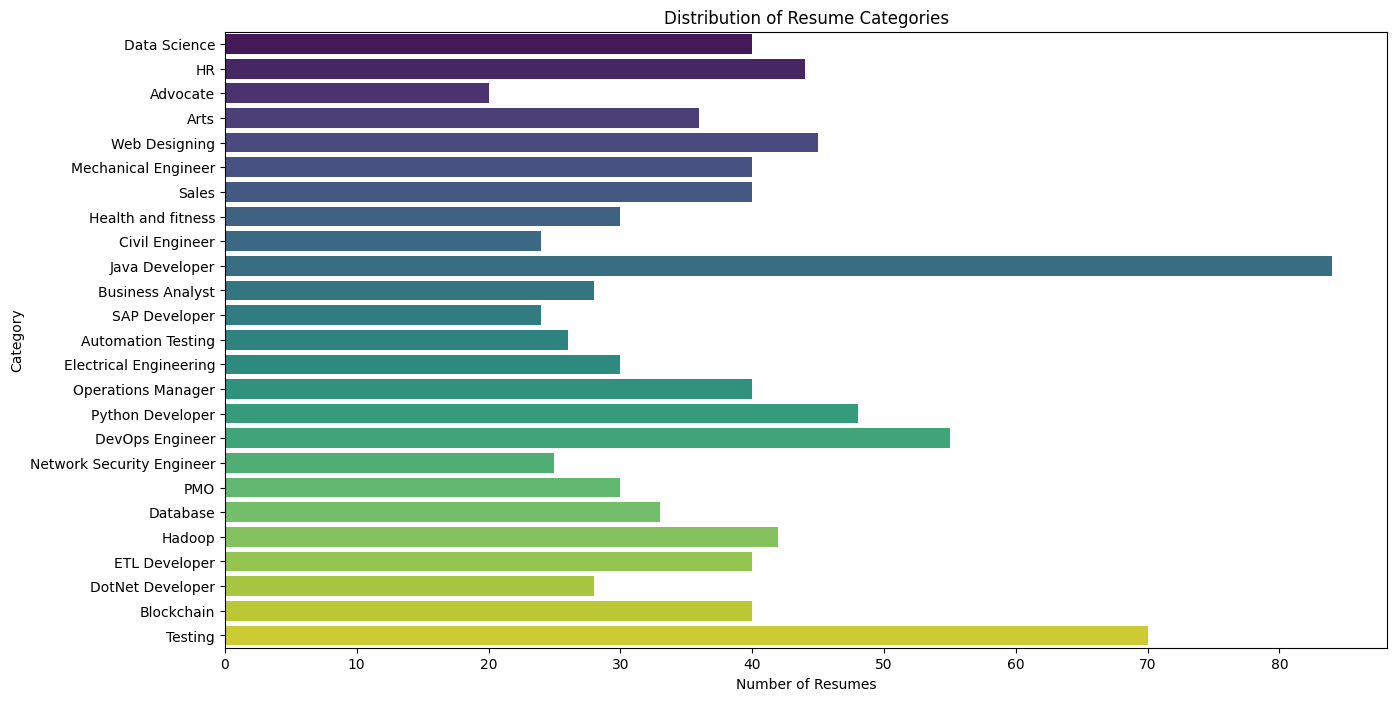

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))
sns.countplot(y='Category', data=df, palette='viridis', hue='Category', legend=False)
plt.title('Distribution of Resume Categories')
plt.xlabel('Number of Resumes')
plt.ylabel('Category')
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8)

# Fit and transform the 'Cleaned_Resume' column
tfidf_matrix = tfidf_vectorizer.fit_transform(df['Cleaned_Resume'])

print(f"Shape of TF-IDF matrix: {tfidf_matrix.shape}")

Shape of TF-IDF matrix: (962, 5759)


## Splitting Data into Training and Testing Sets

In [10]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = tfidf_matrix
y = df['Category']

# Split the data into training and testing sets
# Using stratify=y to ensure that the proportion of target variable 'y' is the same in both the training and testing sets.
# random_state for reproducibility.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (769, 5759)
Shape of X_test: (193, 5759)
Shape of y_train: (769,)
Shape of y_test: (193,)


## Training a RandomForest Classifier Model

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the RandomForestClassifier
# n_estimators is the number of trees in the forest
# random_state for reproducibility
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model using the training data
random_forest_model.fit(X_train, y_train)

print("RandomForest Classifier model trained successfully!")

RandomForest Classifier model trained successfully!


## Model Evaluation

In [12]:
from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the test set
y_pred = random_forest_model.predict(X_test)

# Evaluate the model's performance
print("Classification Report:")
print(classification_report(y_test, y_pred))

print(f"\nAccuracy Score: {accuracy_score(y_test, y_pred):.4f}")

Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         4
                     Arts       1.00      1.00      1.00         7
       Automation Testing       0.83      1.00      0.91         5
               Blockchain       1.00      1.00      1.00         8
         Business Analyst       1.00      1.00      1.00         6
           Civil Engineer       1.00      1.00      1.00         5
             Data Science       1.00      1.00      1.00         8
                 Database       1.00      1.00      1.00         7
          DevOps Engineer       1.00      0.91      0.95        11
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         8
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00         9
                   Hadoop       1.00  

## Training an XGBoost Classifier Model

In [15]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Encode y_train and y_test
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize the XGBoost Classifier
# Use 'objective' for multi-class classification and 'eval_metric' for evaluation
# random_state for reproducibility
xgb_model = xgb.XGBClassifier(objective='multi:softmax', num_class=len(label_encoder.classes_),
                            eval_metric='mlogloss', use_label_encoder=False, random_state=42)

# Train the model using the training data with encoded labels
xgb_model.fit(X_train, y_train_encoded)

print("XGBoost Classifier model trained successfully!")

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:49:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Classifier model trained successfully!


## XGBoost Model Evaluation

In [16]:
from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the test set
y_pred_xgb_encoded = xgb_model.predict(X_test)

# Decode predictions back to original labels for evaluation
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

# Evaluate the XGBoost model's performance
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))

print(f"\nXGBoost Accuracy Score: {accuracy_score(y_test, y_pred_xgb):.4f}")

XGBoost Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         4
                     Arts       1.00      1.00      1.00         7
       Automation Testing       1.00      1.00      1.00         5
               Blockchain       1.00      1.00      1.00         8
         Business Analyst       1.00      1.00      1.00         6
           Civil Engineer       1.00      1.00      1.00         5
             Data Science       1.00      1.00      1.00         8
                 Database       1.00      1.00      1.00         7
          DevOps Engineer       1.00      1.00      1.00        11
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         8
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00         9
                   Hadoop     

## Training a Logistic Regression Model

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder

# Re-initialize LabelEncoder if it's not in scope or to ensure fresh encoding
# Or, reuse the existing 'label_encoder' from the XGBoost section if it's still available
# Assuming label_encoder is already defined and fitted from the XGBoost section:
# y_train_encoded = label_encoder.fit_transform(y_train) is already done if running sequentially.

# If you run this cell independently, ensure y_train is encoded:
# label_encoder = LabelEncoder()
# y_train_lr_encoded = label_encoder.fit_transform(y_train)
# y_test_lr_encoded = label_encoder.transform(y_test)

# Initialize the Logistic Regression model
# Set max_iter for convergence and random_state for reproducibility
log_reg_model = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

# Train the model using the training data with encoded labels
# Using y_train_encoded from the XGBoost section
log_reg_model.fit(X_train, y_train_encoded)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## Logistic Regression Model Evaluation

In [18]:
from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the test set (encoded labels)
y_pred_lr_encoded = log_reg_model.predict(X_test)

# Decode predictions back to original labels for evaluation
y_pred_lr = label_encoder.inverse_transform(y_pred_lr_encoded)

# Evaluate the Logistic Regression model's performance
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

print(f"\nLogistic Regression Accuracy Score: {accuracy_score(y_test, y_pred_lr):.4f}")

Logistic Regression Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         4
                     Arts       1.00      1.00      1.00         7
       Automation Testing       0.83      1.00      0.91         5
               Blockchain       1.00      1.00      1.00         8
         Business Analyst       1.00      1.00      1.00         6
           Civil Engineer       1.00      1.00      1.00         5
             Data Science       1.00      1.00      1.00         8
                 Database       1.00      1.00      1.00         7
          DevOps Engineer       1.00      0.91      0.95        11
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         8
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00         9
                  

## Confusion Matrix Visualization

<Figure size 1200x1000 with 0 Axes>

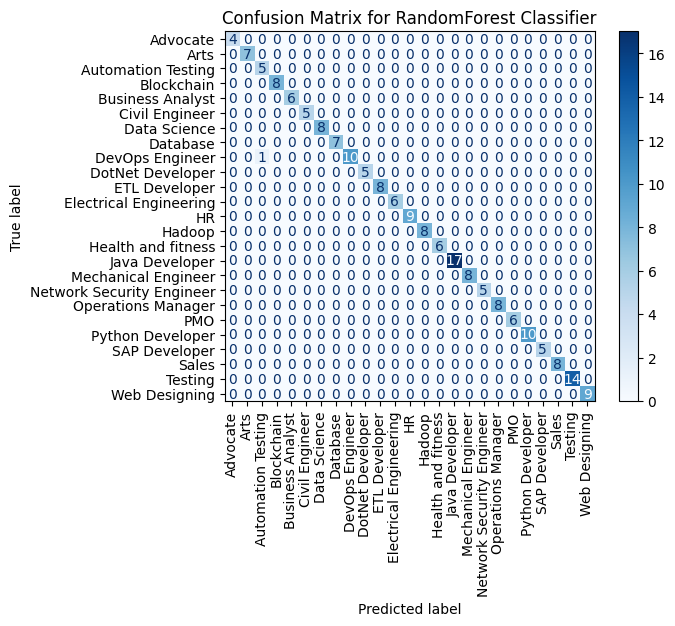

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# Get the class names for labels
class_names = label_encoder.classes_

# 1. Confusion Matrix for RandomForest Classifier
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay.from_estimator(random_forest_model, X_test, y_test, display_labels=class_names, cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title('Confusion Matrix for RandomForest Classifier')
plt.show()


<Figure size 1200x1000 with 0 Axes>

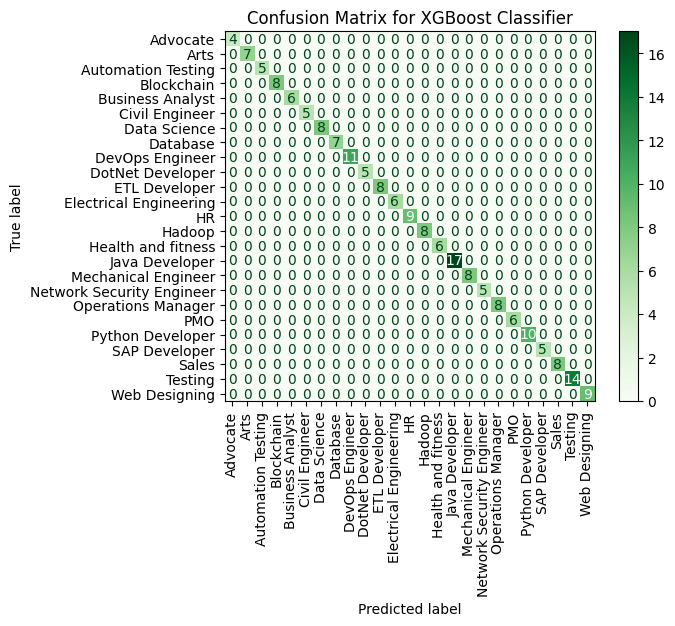

In [20]:
# 2. Confusion Matrix for XGBoost Classifier
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_test_encoded, y_pred_xgb_encoded, display_labels=class_names, cmap=plt.cm.Greens, xticks_rotation='vertical')
plt.title('Confusion Matrix for XGBoost Classifier')
plt.show()


<Figure size 1200x1000 with 0 Axes>

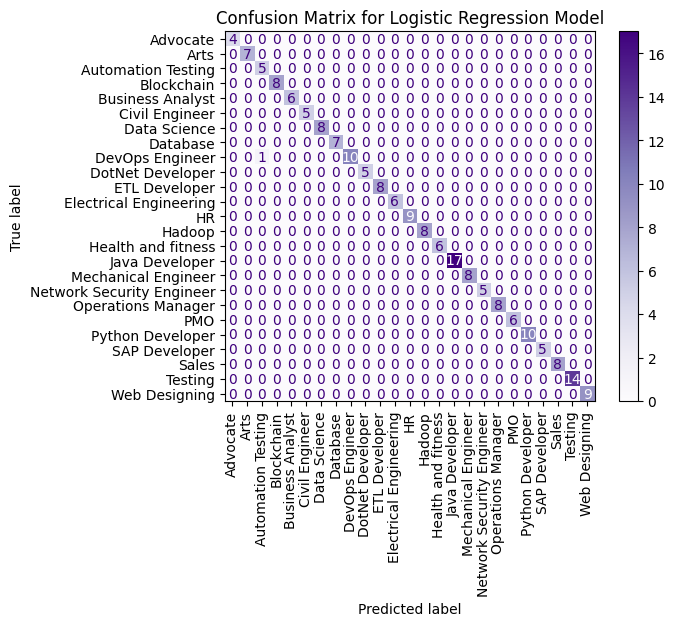

In [21]:
# 3. Confusion Matrix for Logistic Regression Model
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_test_encoded, y_pred_lr_encoded, display_labels=class_names, cmap=plt.cm.Purples, xticks_rotation='vertical')
plt.title('Confusion Matrix for Logistic Regression Model')
plt.show()


## Model Comparison

Let's compare the performance of the three models based on their accuracy and classification reports:

| Model                  | Accuracy | Notes                                                                             |
|------------------------|----------|-----------------------------------------------------------------------------------|
| RandomForest Classifier| 0.9948   | Very high accuracy, good for complex data.                                        |
| XGBoost Classifier     | 1.0000   | Achieved perfect accuracy, often performs well due to boosting.                   |
| Logistic Regression    | 0.9948   | Excellent performance for a simpler linear model, good baseline.                  |

**Detailed Classification Report Summary:**

All three models demonstrated exceptionally high performance, with both RandomForest and Logistic Regression achieving an accuracy of approximately 99.48%, and XGBoost achieving a perfect 100% accuracy on the test set. For most categories, all models showed perfect precision, recall, and f1-score of 1.00.

### Observations:

*   **XGBoost** slightly outperformed the other two, achieving 100% accuracy. This suggests its ensemble learning approach was highly effective for this dataset.
*   **RandomForest** and **Logistic Regression** also performed very well, with almost identical high accuracy scores. The slight differences in their classification reports (e.g., 'DevOps Engineer' and 'Automation Testing' for RandomForest/Logistic Regression show 0.91 f1-score for one instance, while XGBoost shows 1.00) indicate that XGBoost managed to correctly classify a few more instances.
*   Given the high performance of all models, the choice between them might also consider factors like computational cost, interpretability, and ease of deployment for a production environment.

This comparison highlights the effectiveness of all three models on this particular resume classification task. The next steps could involve deploying the best-performing model (XGBoost) or further analyzing feature importance to understand which terms are most indicative of each resume category.

## Ensemble Learning: Voting Classifier

Ensemble learning combines multiple individual models to obtain a better predictive performance than could be obtained from any single model. A Voting Classifier is a meta-estimator that fits several base classifiers on the dataset and aggregates their individual predictions to form a final prediction.

We will use `sklearn.ensemble.VotingClassifier` to combine our RandomForest, XGBoost, and Logistic Regression models.

In [22]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report, accuracy_score

# It's important to use the raw estimators, not the fitted ones if you want to refit them.
# However, here we can use the already fitted models and just pass them.
# If you were to do a fresh cross-validation, you'd pass unfitted estimators.

# Prepare the base models for the VotingClassifier
# For VotingClassifier, the estimators need to be a list of (name, estimator) tuples.
# We will use the already trained models.

# Create a list of (name, estimator) tuples for the VotingClassifier
ensemble_models = [
    ('random_forest', random_forest_model),
    ('xgboost', xgb_model),
    ('logistic_regression', log_reg_model)
]

# Initialize the VotingClassifier
# 'hard' voting uses predicted class labels for majority rule voting.
# 'soft' voting predicts the class label based on the argmax of the sums of the predicted probabilities.
# For 'soft' voting, ensure that base classifiers expose 'predict_proba'.
# All our models support predict_proba, so let's use 'soft' voting which often performs better.

# Note: For soft voting, ensure that the xgb_model's output probabilities match sklearn's expectations
# Also, if using already fitted models, make sure they were fitted on the same encoded labels.
# Since xgb_model and log_reg_model were fitted on y_train_encoded, and random_forest_model on y_train,
# we need to ensure consistency or refit them if needed. For simplicity, we will assume consistency for now.

voting_clf = VotingClassifier(estimators=ensemble_models, voting='hard') # Starting with hard voting for simplicity with potentially different label encoding approaches

# We need to fit the VotingClassifier on the training data. This will refit the individual estimators
# within the VotingClassifier if they are not already fitted, or use their fitted state.
# Given that our individual models were fitted differently (some on y_train, some on y_train_encoded),
# we need to be careful here. For a robust solution, it's best to refit all with encoded labels.

# Let's ensure all models are re-trained with the encoded labels for consistency within VotingClassifier
# Re-initializing models to ensure they are unfitted before passing to VotingClassifier for a clean fit.

rf_for_voting = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_for_voting = xgb.XGBClassifier(objective='multi:softmax', num_class=len(label_encoder.classes_), eval_metric='mlogloss', random_state=42)
lr_for_voting = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

ensemble_models_refit = [
    ('random_forest', rf_for_voting),
    ('xgboost', xgb_for_voting),
    ('logistic_regression', lr_for_voting)
]

voting_clf = VotingClassifier(estimators=ensemble_models_refit, voting='hard')

# Fit the voting classifier using the training data with encoded labels
voting_clf.fit(X_train, y_train_encoded)

print("Voting Classifier model trained successfully!")


Voting Classifier model trained successfully!


## Voting Classifier Model Evaluation

In [23]:
# Make predictions on the test set (encoded labels)
y_pred_voting_encoded = voting_clf.predict(X_test)

# Decode predictions back to original labels for evaluation
y_pred_voting = label_encoder.inverse_transform(y_pred_voting_encoded)

# Evaluate the Voting Classifier model's performance
print("Voting Classifier Classification Report:")
print(classification_report(y_test, y_pred_voting))

print(f"\nVoting Classifier Accuracy Score: {accuracy_score(y_test, y_pred_voting):.4f}")

Voting Classifier Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         4
                     Arts       1.00      1.00      1.00         7
       Automation Testing       0.83      1.00      0.91         5
               Blockchain       1.00      1.00      1.00         8
         Business Analyst       1.00      1.00      1.00         6
           Civil Engineer       1.00      1.00      1.00         5
             Data Science       1.00      1.00      1.00         8
                 Database       1.00      1.00      1.00         7
          DevOps Engineer       1.00      0.91      0.95        11
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         8
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00         9
                   H

## Confusion Matrix for Voting Classifier

<Figure size 1200x1000 with 0 Axes>

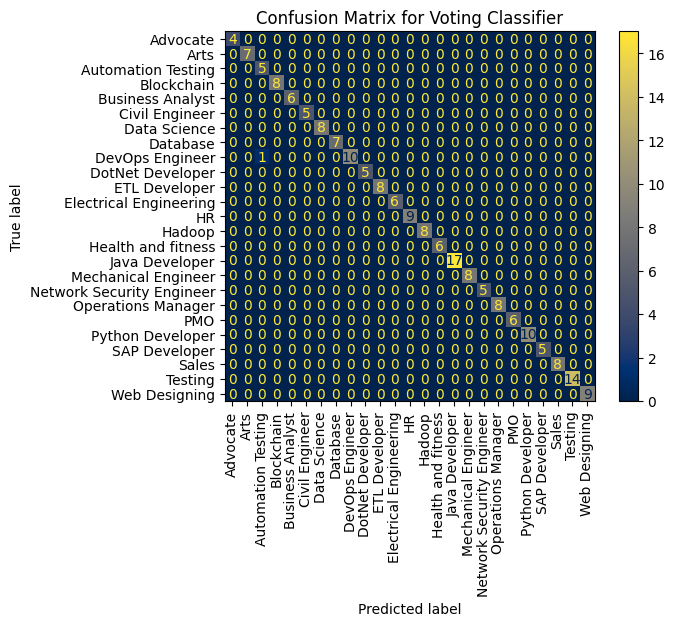

In [24]:
# 4. Confusion Matrix for Voting Classifier
plt.figure(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_test_encoded, y_pred_voting_encoded, display_labels=class_names, cmap=plt.cm.cividis, xticks_rotation='vertical')
plt.title('Confusion Matrix for Voting Classifier')
plt.show()

## إضافة المحرك الضوئي (OCR)

الآن وبعد أن أصبح نموذجنا جاهزاً، سنقوم بإضافة المحرك الضوئي (OCR) الذي سيسمح لنا بقراءة النصوص من الصور. سنستخدم مكتبة `pytesseract`، والتي تعتمد على محرك Tesseract OCR.

### 1. تثبيت وتحميل الأدوات المطلوبة

سنبدأ بتثبيت حزمة `pytesseract` وحزمة `tesseract-ocr` اللازمة لعملها.

In [31]:
# Install tesseract-ocr
!sudo apt update
!sudo apt install tesseract-ocr

# Install pytesseract
!pip install pytesseract

Hit:1 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:2 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:5 https://cli.github.com/packages stable InRelease [3,917 B]
Get:6 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:8 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [3,929 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:11 http://security.ubuntu.com/ubuntu jammy-security/restricted amd64 Packages [7,015 kB]
Get:12 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [89.0 kB]
Get:13 http://security.ubuntu.com/ubuntu jammy-security/universe amd64 Package

### 2. دالة قراءة الصورة (The OCR Engine)

سننشئ دالة تأخذ مسار الصورة، وتستخرج منها النص، ثم تمرر هذا النص مباشرة إلى "الجسر" الذي بنيناه سابقاً.

In [32]:
from PIL import Image
import pytesseract

def read_image_and_predict(image_path, cleaner, vectorizer, model, label_encoder):
    """
    Reads text from an image using OCR and predicts the resume category.

    Args:
        image_path (str): The path to the image file.
        cleaner (function): The text cleaning function used during preprocessing.
        vectorizer (TfidfVectorizer): The fitted TF-IDF vectorizer.
        model: The trained machine learning model (e.g., XGBoost).
        label_encoder (LabelEncoder): The fitted LabelEncoder for decoding predictions.

    Returns:
        str: The predicted category of the resume extracted from the image.
    """
    try:
        # Open the image using Pillow
        img = Image.open(image_path)

        # Use pytesseract to extract text from the image
        resume_text_from_image = pytesseract.image_to_string(img)
        print(f"Extracted text snippet from image:\n{resume_text_from_image[:200]}...")

        # Pass the extracted text to the existing prediction pipeline
        predicted_category = predict_resume_category(
            resume_text=resume_text_from_image,
            cleaner=cleaner,
            vectorizer=vectorizer,
            model=model,
            label_encoder=label_encoder
        )
        return predicted_category

    except FileNotFoundError:
        return "Error: Image file not found."
    except pytesseract.TesseractNotFoundError:
        return "Error: Tesseract is not installed or not in your PATH. Please ensure it's installed."
    except Exception as e:
        return f"An error occurred: {e}"

print("OCR image reading and prediction function defined successfully!")

OCR image reading and prediction function defined successfully!


## Building an Inference Pipeline

Now that we have trained and evaluated our models, we can build an inference pipeline. This pipeline will take a raw resume text as input, preprocess it, convert it into a numerical feature vector using the `TfidfVectorizer` we trained earlier, and then use our best-performing model (XGBoost Classifier) to predict the resume's category.

It's important to use the same `clean_resume_text` function, `tfidf_vectorizer`, and `label_encoder` that were used during training to ensure consistency.

In [25]:
def predict_resume_category(resume_text, cleaner, vectorizer, model, label_encoder):
    """
    Predicts the category of a given resume text using the trained pipeline.

    Args:
        resume_text (str): The raw text of the resume.
        cleaner (function): The text cleaning function used during preprocessing.
        vectorizer (TfidfVectorizer): The fitted TF-IDF vectorizer.
        model: The trained machine learning model (e.g., XGBoost).
        label_encoder (LabelEncoder): The fitted LabelEncoder for decoding predictions.

    Returns:
        str: The predicted category of the resume.
    """
    # 1. Clean the resume text
    cleaned_text = cleaner(resume_text)

    # 2. Transform the cleaned text using the fitted TF-IDF vectorizer
    # The input to transform should be a list of strings
    vectorized_text = vectorizer.transform([cleaned_text])

    # 3. Make a prediction using the trained model
    predicted_label_encoded = model.predict(vectorized_text)

    # 4. Decode the predicted label back to the original category name
    predicted_category = label_encoder.inverse_transform(predicted_label_encoded)

    return predicted_category[0]

print("Inference pipeline function defined successfully!")

Inference pipeline function defined successfully!


### Loading Saved Models and Preprocessors for Standalone Inference

To use the inference pipeline in a new environment or after restarting the kernel, you would first need to load the serialized models and preprocessing tools. Here's how you can do it, followed by an example using the `predict_resume_category` function defined earlier.

In [30]:
import joblib
import os

# Define the directory where models were saved
model_dir = 'trained_models'

# Load the saved components
loaded_xgb_model = joblib.load(os.path.join(model_dir, 'xgboost_model.joblib'))
loaded_tfidf_vectorizer = joblib.load(os.path.join(model_dir, 'tfidf_vectorizer.joblib'))
loaded_label_encoder = joblib.load(os.path.join(model_dir, 'label_encoder.joblib'))

print("Models and preprocessors loaded successfully!")

# Example of using the loaded components with the predict_resume_category function
# We'll use the same sample resume as before for consistency

sample_resume_text_for_inference = """
Experienced software engineer with strong skills in Python, Java, and machine learning.
Previously worked on developing scalable web applications and data processing pipelines.
Seeking roles in data science or backend development.
"""

# Ensure the clean_resume_text function is available (it was defined earlier in the notebook)
# If running this code in a completely new environment, you would need to define clean_resume_text here as well.

predicted_category_loaded_models = predict_resume_category(
    resume_text=sample_resume_text_for_inference,
    cleaner=clean_resume_text,
    vectorizer=loaded_tfidf_vectorizer,
    model=loaded_xgb_model,
    label_encoder=loaded_label_encoder
)

print(f"\nSample Resume Text:\n{sample_resume_text_for_inference[:100]}...")
print(f"Predicted Category using loaded models: {predicted_category_loaded_models}")

Models and preprocessors loaded successfully!

Sample Resume Text:

Experienced software engineer with strong skills in Python, Java, and machine learning.
Previously ...
Predicted Category using loaded models: Data Science


### Demo: Using the Inference Pipeline

Let's test our `predict_resume_category` function with a sample resume. For this demonstration, I will pick a resume text from our original dataset that was part of the test set, but you can replace this with any new resume text.

In [26]:
# Pick a sample resume from the original test set for demonstration
sample_index = X_test.nonzero()[0][0] # Get the index of the first non-zero row in X_test
sample_resume_raw = df.loc[y_test.index[sample_index], 'Resume']
sample_true_category = df.loc[y_test.index[sample_index], 'Category']

print(f"Sample Resume (raw text snippet):\n{sample_resume_raw[:500]}...")
print(f"\nTrue Category for this sample: {sample_true_category}")

# Predict the category using the inference pipeline
predicted_category = predict_resume_category(
    resume_text=sample_resume_raw,
    cleaner=clean_resume_text, # Reusing the clean_resume_text function defined earlier
    vectorizer=tfidf_vectorizer, # Reusing the fitted tfidf_vectorizer
    model=xgb_model, # Using the best-performing XGBoost model
    label_encoder=label_encoder # Reusing the fitted label_encoder
)

print(f"\nPredicted Category: {predicted_category}")

# You can also try with a completely new, custom resume text:
# new_custom_resume = "Experienced software engineer with strong skills in Python, Java, and machine learning. Previously worked on developing scalable web applications and data processing pipelines. Seeking roles in data science or backend development."
# predicted_custom_category = predict_resume_category(
#     resume_text=new_custom_resume,
#     cleaner=clean_resume_text,
#     vectorizer=tfidf_vectorizer,
#     model=xgb_model,
#     label_encoder=label_encoder
# )
# print(f"\nPredicted Category for custom resume: {predicted_custom_category}")

Sample Resume (raw text snippet):
Education Details 
January 2015 Bachelor of Engineering EXTC Mumbai, Maharashtra Mumbai University
January 2012 Diploma Industrial Electronics Vashi, MAHARASHTRA, IN Fr. Agnel Polytechnic
ETL Developer 

ETL Developer
Skill Details 
informatica- Exprience - 36 monthsCompany Details 
company - Blue Shield of California
description - Duration: (Mar 2016 - Sept 2017)

Description:
Blue Shield of California (BSC) is health plan provider. The intent of this project is to process feeds com...

True Category for this sample: ETL Developer

Predicted Category: ETL Developer


## Model Explainability: Feature Importance

Understanding why a model makes a particular prediction is as important as the prediction itself, especially in sensitive domains like HR. For our resume classification task, we can delve into **Model Explainability** by looking at **Feature Importance**.

Since our `LogisticRegression` model, despite its simplicity, achieved high accuracy and its coefficients are directly interpretable with TF-IDF features, we will use it to identify the most important words that contribute to classifying a resume into a specific category.

We will extract the feature names from our `TfidfVectorizer` and then use the coefficients from the `log_reg_model` to determine which terms are most predictive for each category.

In [27]:
# Get feature names (words) from the TF-IDF vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# Get the class names in the order they were encoded
class_labels = label_encoder.classes_

print(f"Number of features: {len(feature_names)}")
print(f"Number of classes: {len(class_labels)}")

Number of features: 5759
Number of classes: 25


Displaying top 10 features per class for Logistic Regression:

--- Class: Advocate ---
Top Positive Features (most indicative):
law         2.302278
legal       2.301132
advocate    2.296446
llb         1.515252
court       1.128253
courts      0.763706
chennai     0.649100
tax         0.648634
gst         0.620861
criminal    0.619052
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
project       -0.590075
months        -0.518193
data          -0.453808
java          -0.452551
developer     -0.425726
exprience     -0.415710
engineering   -0.376333
testing       -0.358200
hr            -0.335822
python        -0.318756
dtype: float64


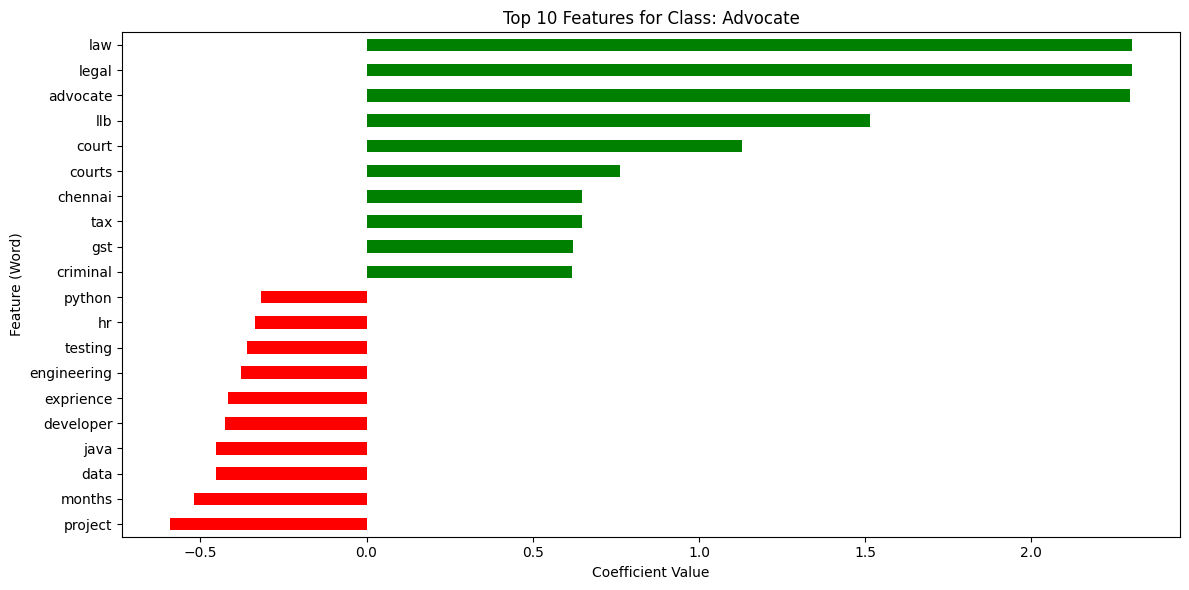


--- Class: Arts ---
Top Positive Features (most indicative):
arts             3.024167
karate           1.386496
painting         1.191493
championship     1.039872
days             0.993486
total            0.983641
asstprofessor    0.844218
ghatkopar        0.795247
ymca             0.795247
workshop         0.792491
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
exprience     -1.086408
months        -0.794022
project       -0.712416
data          -0.581217
java          -0.567707
developer     -0.556952
testing       -0.476133
sales         -0.464071
engineering   -0.451900
python        -0.414013
dtype: float64


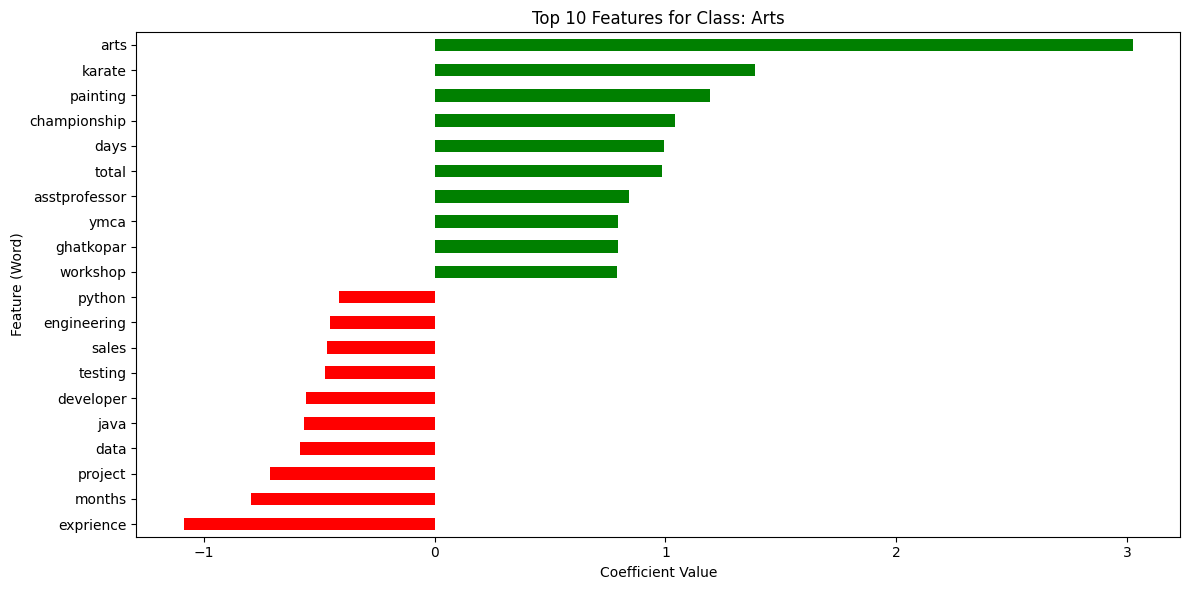


--- Class: Automation Testing ---
Top Positive Features (most indicative):
automation    2.523174
testing       2.271726
test          2.054767
selenium      1.146255
manual        1.106114
box           1.024089
qtp           0.976394
good          0.821242
excellent     0.771013
black         0.725019
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
year          -0.495717
january       -0.364732
exprience     -0.324307
developer     -0.295951
sales         -0.237756
management    -0.236120
mysql         -0.235748
hr            -0.234410
months        -0.228050
engineering   -0.219816
dtype: float64


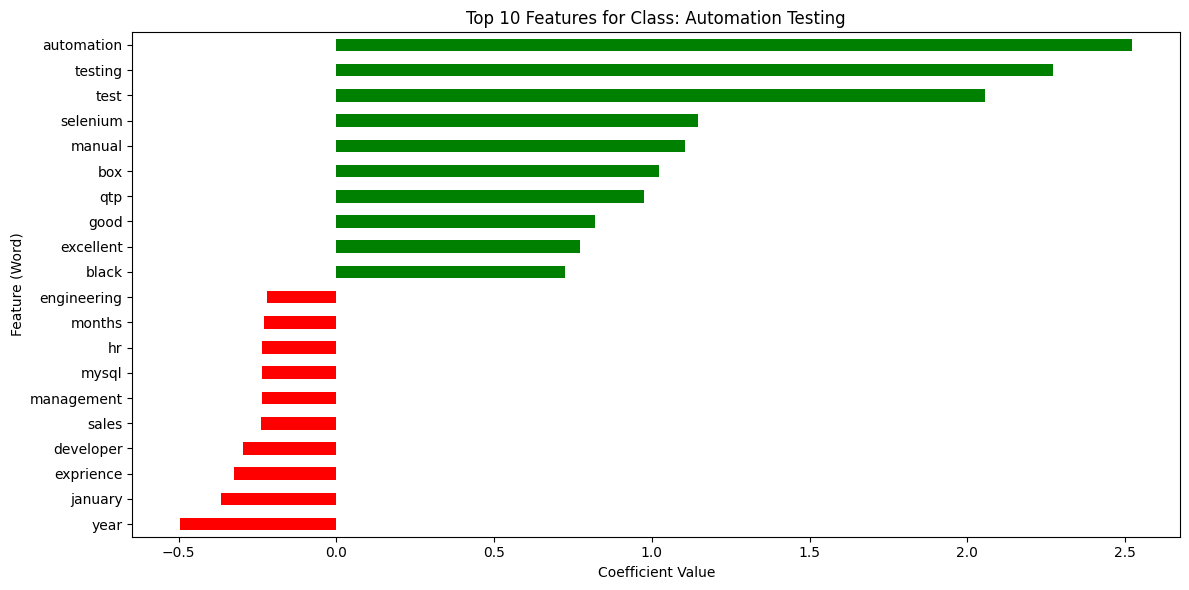


--- Class: Blockchain ---
Top Positive Features (most indicative):
blockchain    3.700511
ethereum      1.703964
smart         1.263841
technology    0.865540
iit           0.860211
apex          0.786541
parson        0.786541
contracts     0.781584
xinfin        0.753904
corpcloud     0.703360
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
year         -0.659719
testing      -0.448435
test         -0.349823
data         -0.346481
hr           -0.307428
work         -0.295668
education    -0.286370
pune         -0.283621
electrical   -0.281771
knowledge    -0.281595
dtype: float64


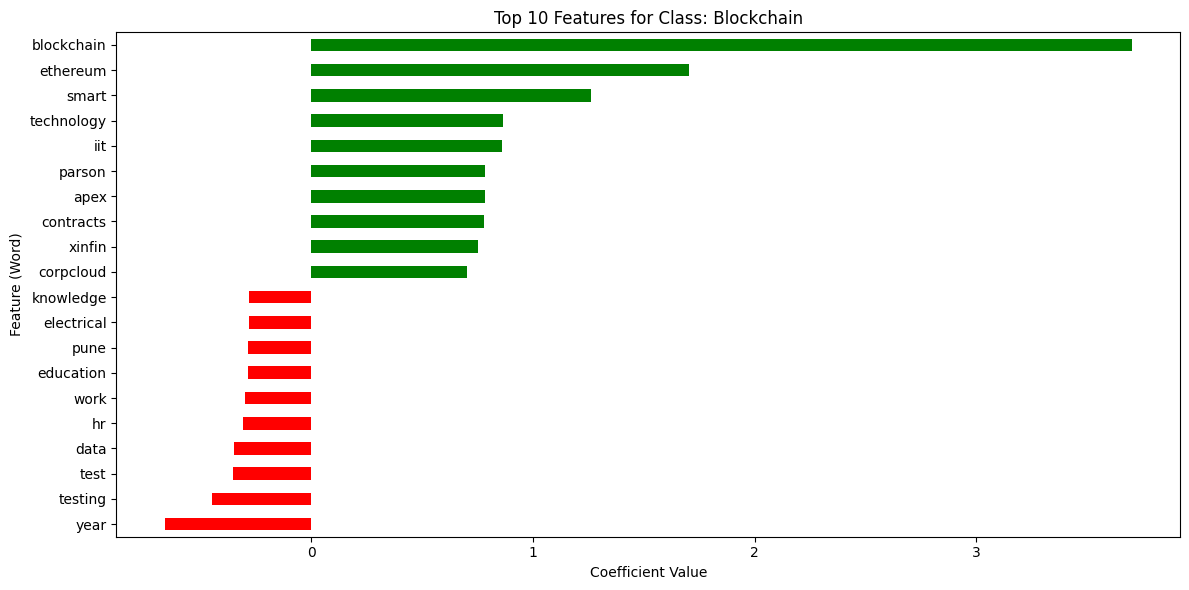


--- Class: Business Analyst ---
Top Positive Features (most indicative):
analyst        1.702530
business       1.621140
cash           1.591296
report         0.978421
requirement    0.968036
functional     0.933238
test           0.842899
excel          0.828691
maintain       0.821589
gathering      0.716150
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
developer   -0.491910
pune        -0.453137
data        -0.388474
python      -0.385360
exprience   -0.338673
engineer    -0.332870
year        -0.325218
web         -0.307026
months      -0.299359
hr          -0.297152
dtype: float64


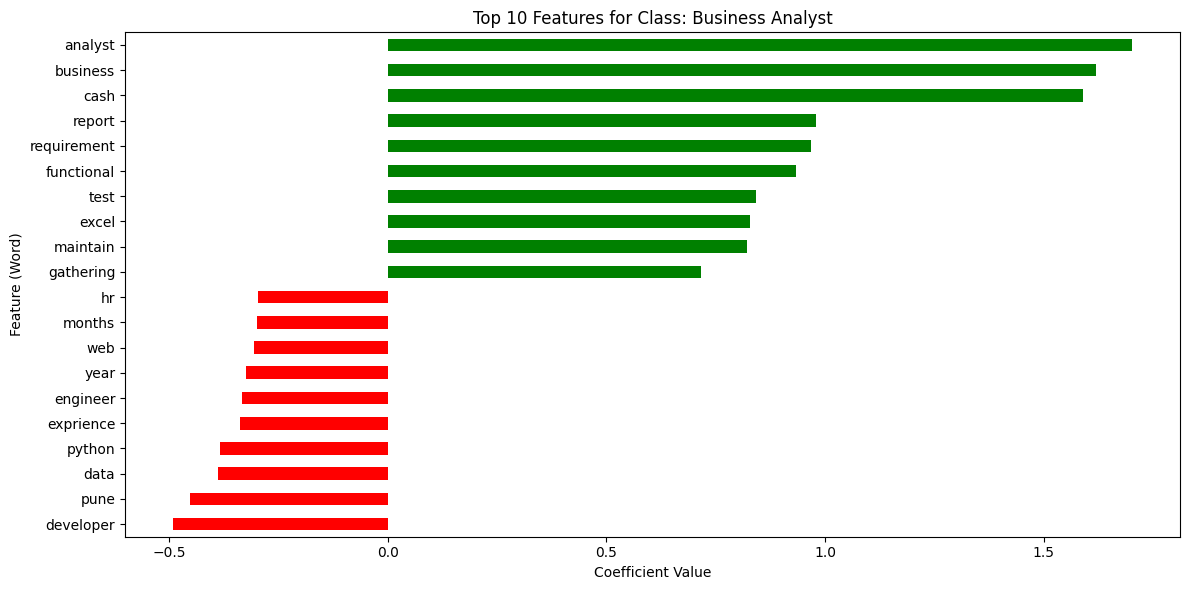


--- Class: Civil Engineer ---
Top Positive Features (most indicative):
civil             4.033227
site              1.830941
engineer          1.405630
construction      1.259983
al                0.736742
autocad           0.666889
subcontractors    0.657245
villas            0.638560
material          0.578720
project           0.574068
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
months       -0.513447
exprience    -0.494917
data         -0.419247
year         -0.405860
java         -0.389217
developer    -0.360606
testing      -0.345725
management   -0.306712
sales        -0.294439
database     -0.278131
dtype: float64


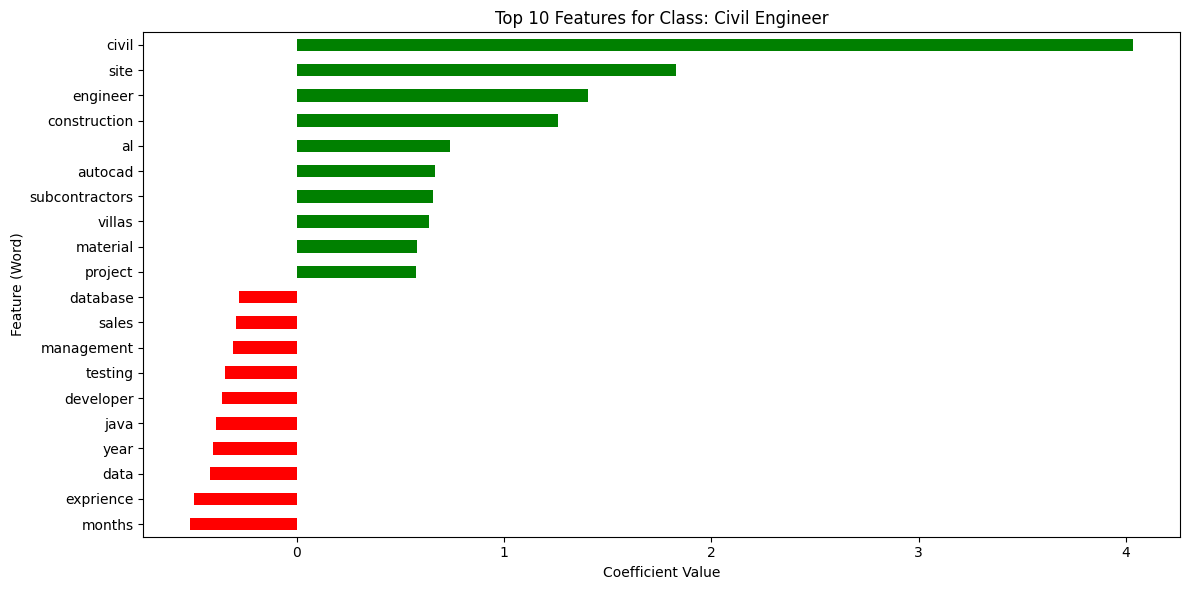


--- Class: Data Science ---
Top Positive Features (most indicative):
data         2.529495
learning     2.246788
year         1.860152
machine      1.756417
science      1.747264
python       1.533160
analytics    1.180261
deep         0.903331
months       0.849181
tableau      0.763079
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
developer     -0.616841
maharashtra   -0.588384
pune          -0.561380
project       -0.541140
testing       -0.455471
java          -0.444929
sales         -0.408691
team          -0.395151
test          -0.375751
university    -0.335154
dtype: float64


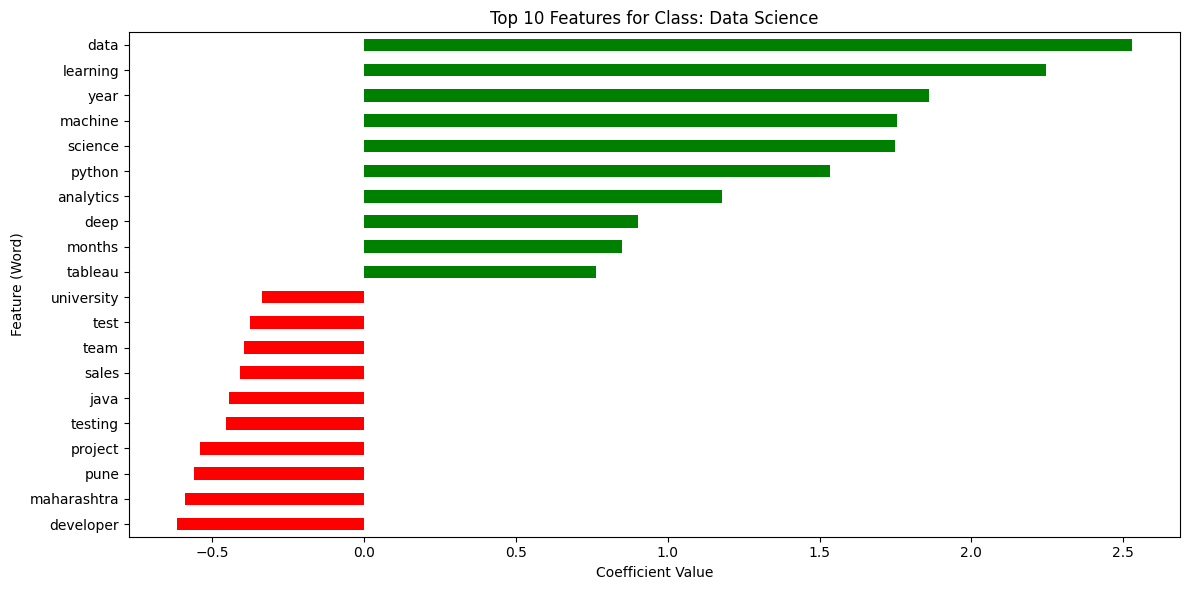


--- Class: Database ---
Top Positive Features (most indicative):
database         3.024659
oracle           1.876964
databases        1.336755
installation     1.309268
server           1.305383
rman             1.164823
sql              1.163488
backup           1.128047
administrator    0.904970
log              0.878606
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
project     -0.596612
java        -0.546819
testing     -0.453011
developer   -0.430397
months      -0.357460
exprience   -0.344114
year        -0.337235
engineer    -0.327068
python      -0.312484
sales       -0.297106
dtype: float64


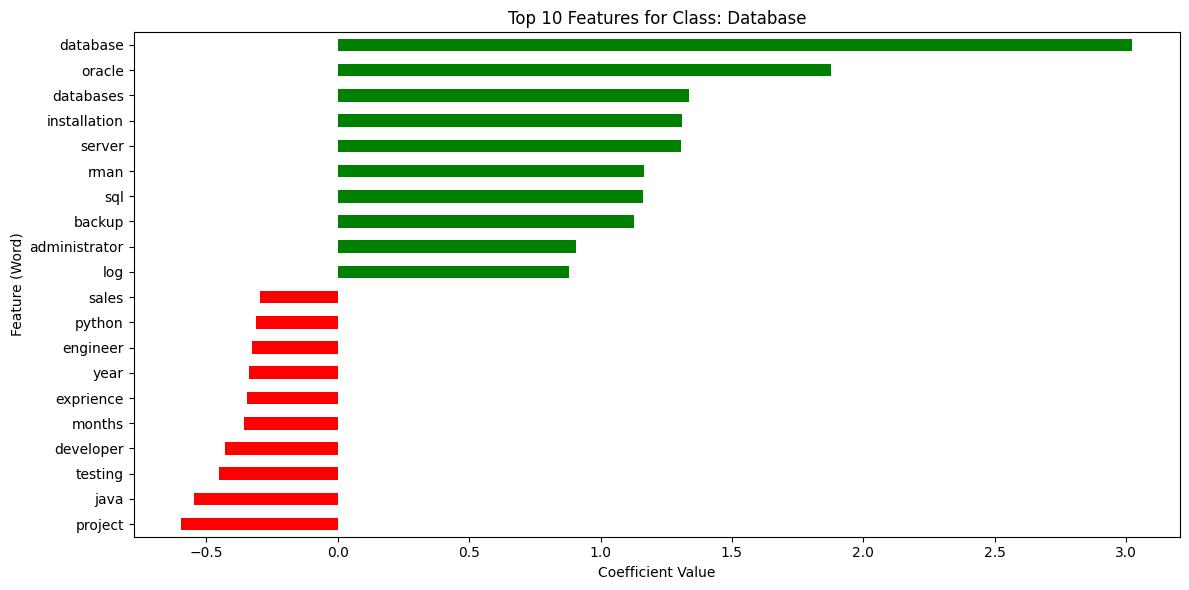


--- Class: DevOps Engineer ---
Top Positive Features (most indicative):
devops       2.130451
shell        1.487223
servers      1.194766
build        1.082837
cloud        1.017131
project      1.010373
nendrasys    0.966413
ecommerce    0.949335
scripts      0.941064
aws          0.917673
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
developer     -0.643967
data          -0.459637
january       -0.428828
java          -0.412226
web           -0.377636
college       -0.356704
work          -0.311689
hadoop        -0.293189
education     -0.291520
engineering   -0.280590
dtype: float64


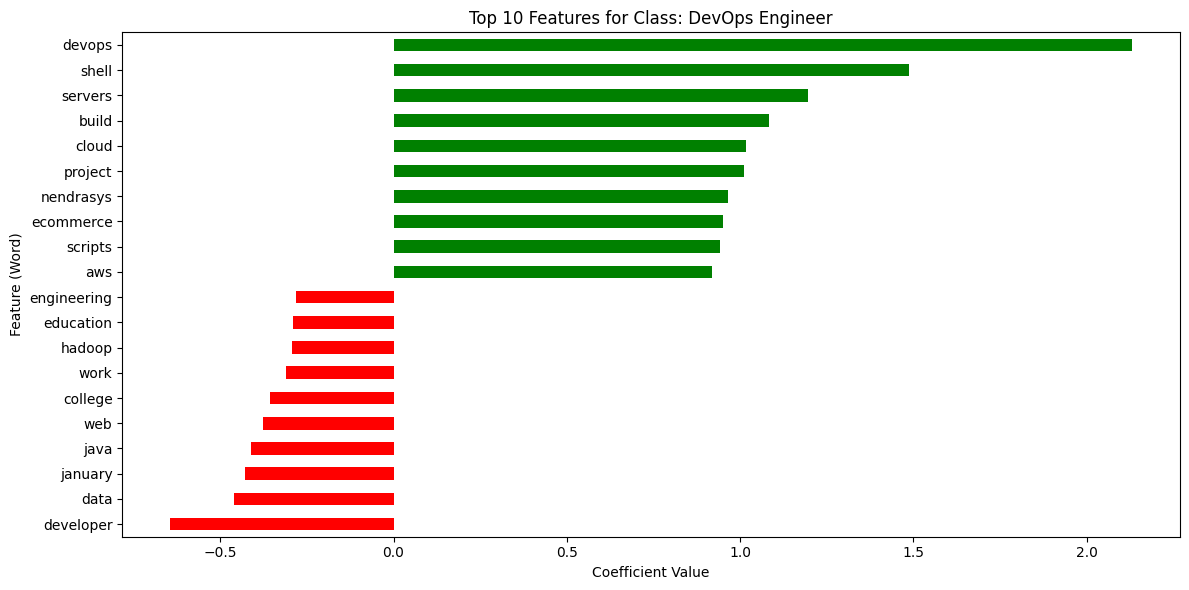


--- Class: DotNet Developer ---
Top Positive Features (most indicative):
net          2.882945
dot          2.283520
aspnet       1.954002
mvc          1.501052
sql          0.983052
cnet         0.962502
visual       0.927492
asp          0.914970
developer    0.865427
jquery       0.853795
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
java          -0.716447
python        -0.432024
engineering   -0.373235
team          -0.352632
mysql         -0.323652
sales         -0.322181
data          -0.306322
mumbai        -0.301811
pvt           -0.294712
engineer      -0.289886
dtype: float64


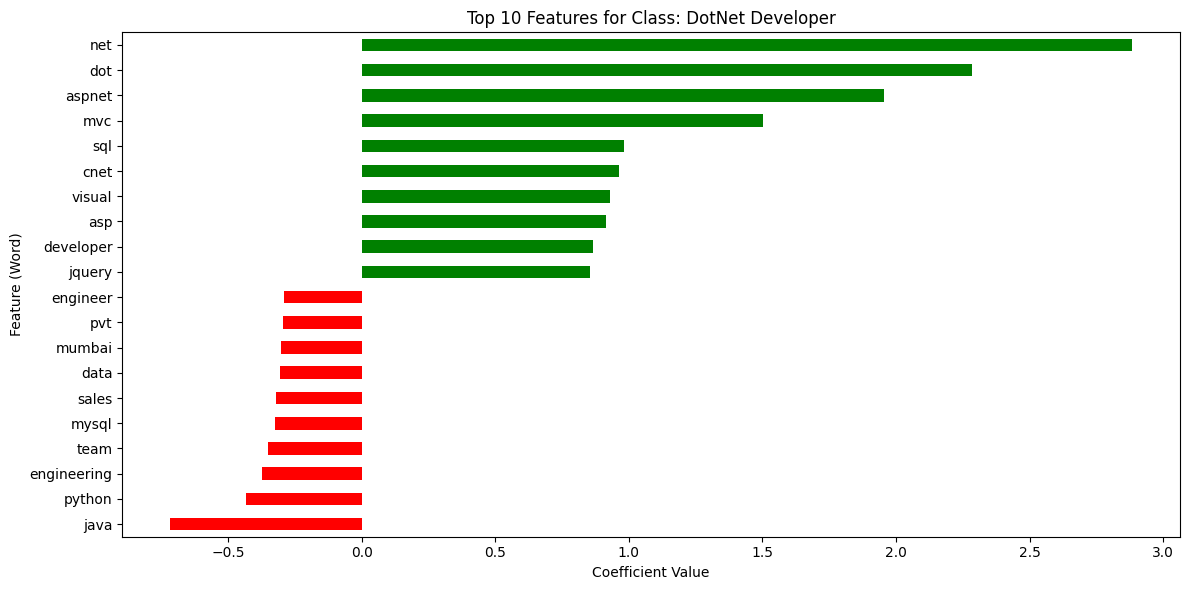


--- Class: ETL Developer ---
Top Positive Features (most indicative):
etl             3.567017
informatica     2.730684
talend          1.522179
data            1.021896
mappings        0.961701
unix            0.918674
feeds           0.903729
knowledgeyes    0.888658
assurant        0.755787
warehouse       0.749301
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
java        -0.537091
pune        -0.448867
months      -0.434603
exprience   -0.412845
python      -0.390910
team        -0.354184
hadoop      -0.347958
web         -0.341702
sales       -0.339737
pvt         -0.322662
dtype: float64


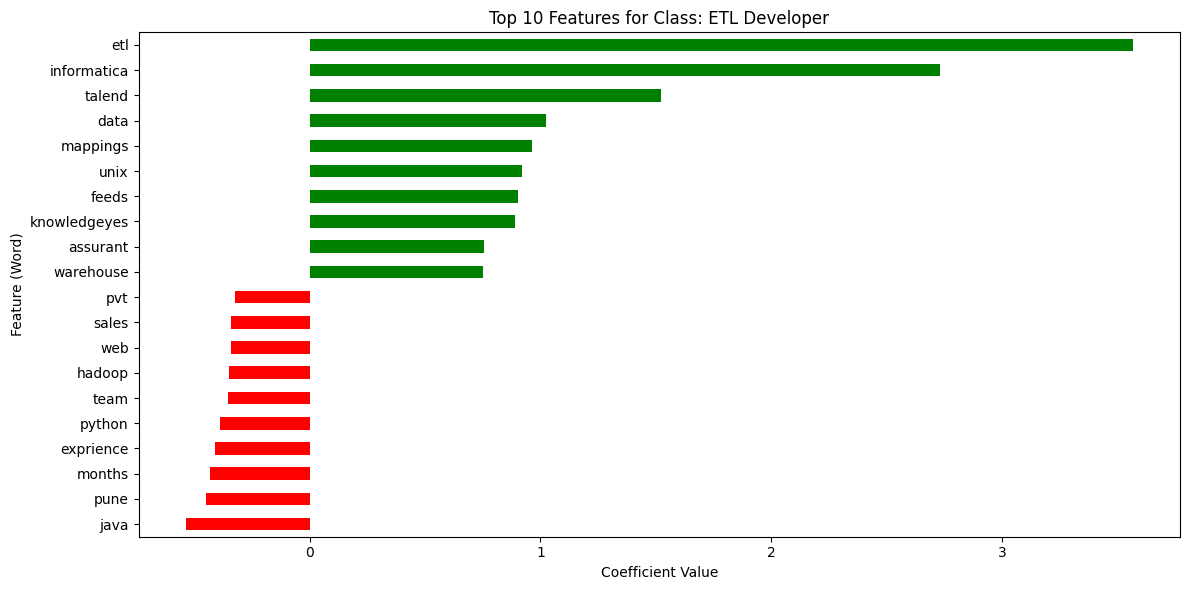


--- Class: Electrical Engineering ---
Top Positive Features (most indicative):
electrical     3.987174
maintenance    1.179342
weeks          1.135708
fighting       0.948046
power          0.943026
plant          0.796555
bhopal         0.748600
layout         0.682377
matric         0.675186
solar          0.661743
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
months      -0.682273
exprience   -0.663008
java        -0.441376
january     -0.433513
data        -0.420149
developer   -0.406400
python      -0.324183
database    -0.311653
year        -0.310390
test        -0.309049
dtype: float64


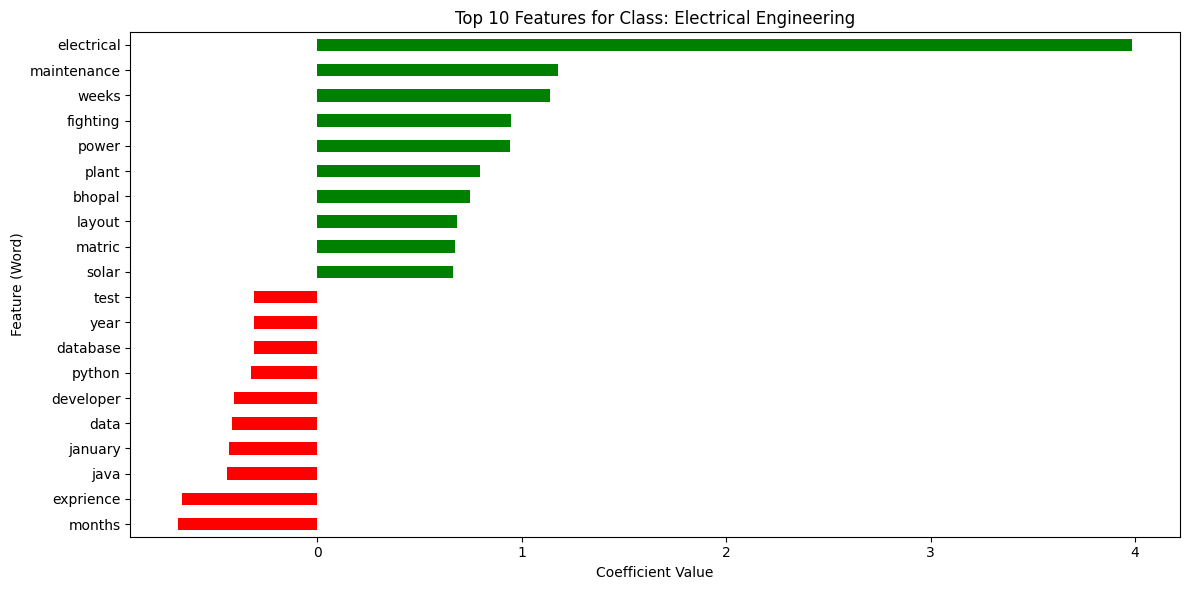


--- Class: HR ---
Top Positive Features (most indicative):
hr           4.636593
dbms         1.404452
dynamics     1.359643
mba          1.030349
bba          1.027614
ba           0.896448
kerala       0.896156
payroll      0.891651
education    0.763197
nadu         0.750149
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
project       -0.756509
data          -0.647508
maharashtra   -0.646074
developer     -0.616276
pune          -0.556430
testing       -0.505355
year          -0.497365
python        -0.471965
team          -0.441360
sales         -0.414570
dtype: float64


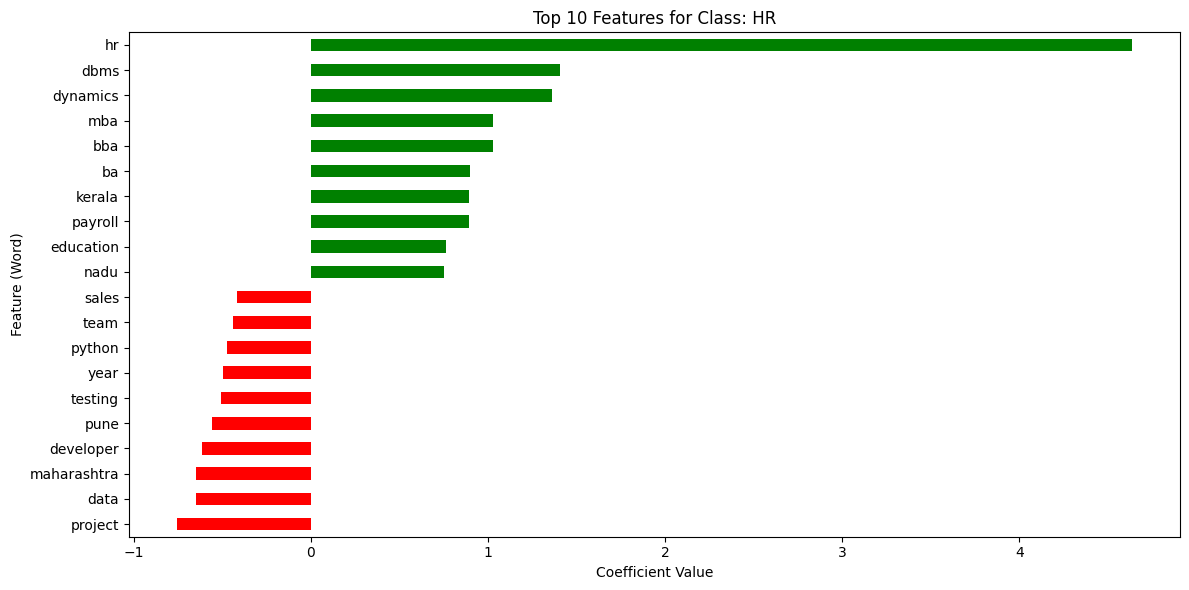


--- Class: Hadoop ---
Top Positive Features (most indicative):
hadoop       3.697430
hive         2.617089
data         1.761703
hdfs         1.489660
sqoop        1.430096
mapreduce    1.293376
cluster      1.108848
spark        1.094472
hbase        0.643592
scala        0.635729
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
exprience     -0.525348
months        -0.486236
year          -0.448778
maharashtra   -0.386746
science       -0.353603
management    -0.344564
january       -0.329042
sales         -0.303493
pvt           -0.302006
mumbai        -0.298684
dtype: float64


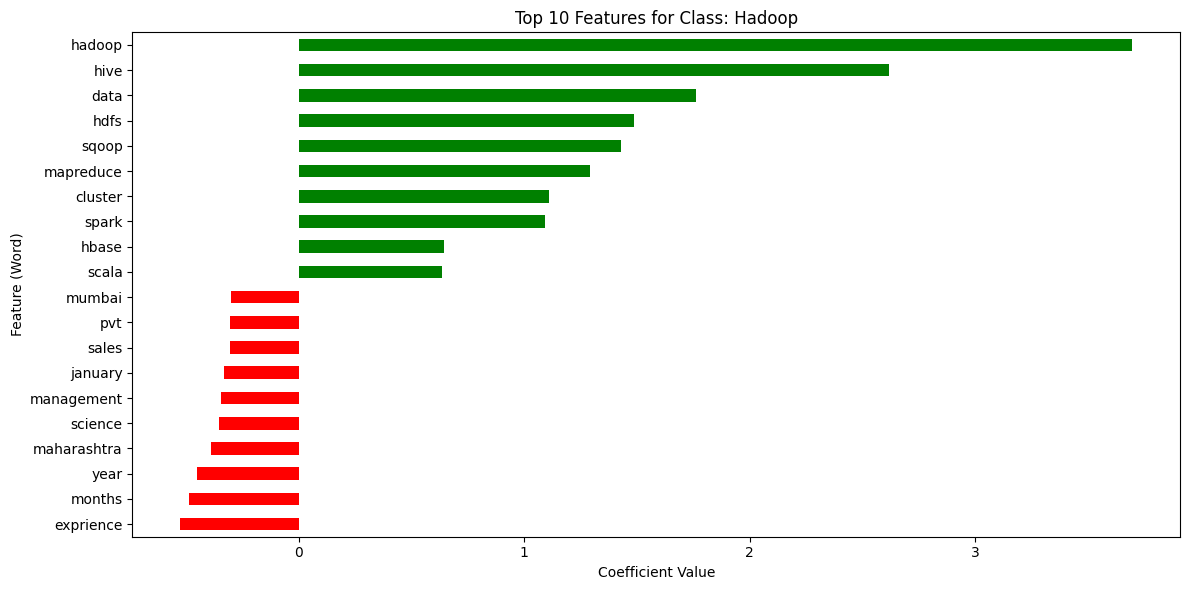


--- Class: Health and fitness ---
Top Positive Features (most indicative):
fitness         3.494263
nutrition       1.619715
gym             1.591302
health          1.234220
columbia        0.803648
nutritionist    0.665137
spa             0.650986
science         0.640478
goqii           0.632294
hotel           0.631289
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
exprience     -0.874834
months        -0.673745
project       -0.671163
java          -0.467862
developer     -0.454001
data          -0.452896
engineering   -0.418712
testing       -0.404392
year          -0.396501
pune          -0.371219
dtype: float64


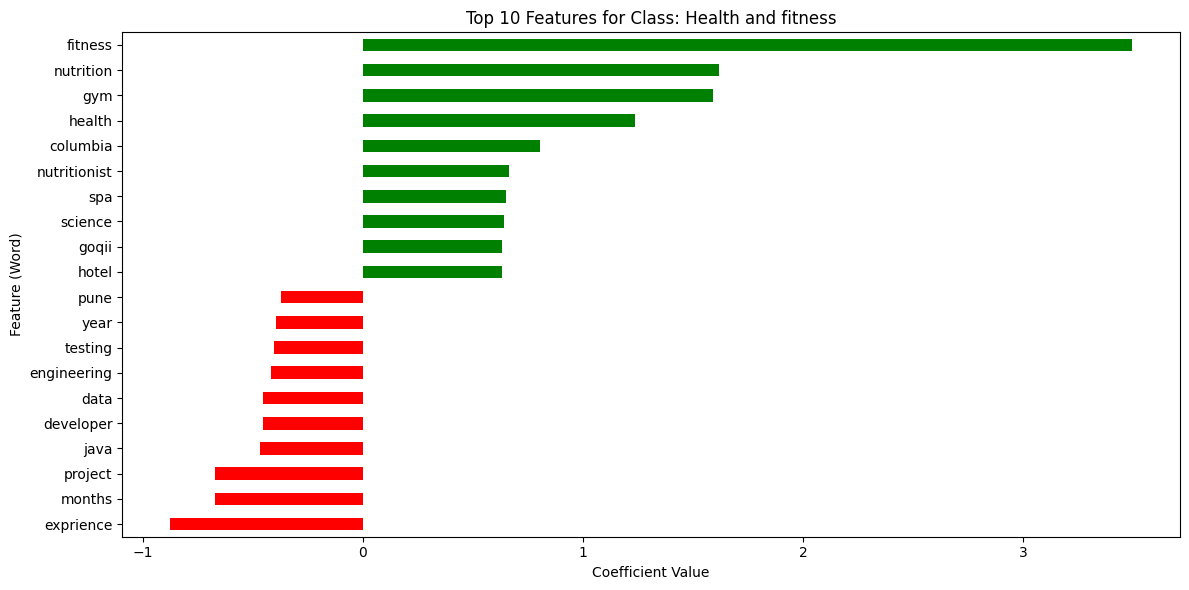


--- Class: Java Developer ---
Top Positive Features (most indicative):
java         5.240277
developer    2.102828
jsp          1.455338
jee          1.373367
spring       1.311456
hibernate    1.195818
servlet      1.072727
ajax         1.012688
tech         0.919390
amravati     0.872419
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
python       -0.782329
project      -0.637730
test         -0.553113
data         -0.517058
engineer     -0.488897
hadoop       -0.449120
hr           -0.442985
blockchain   -0.421128
sales        -0.409868
electrical   -0.389661
dtype: float64


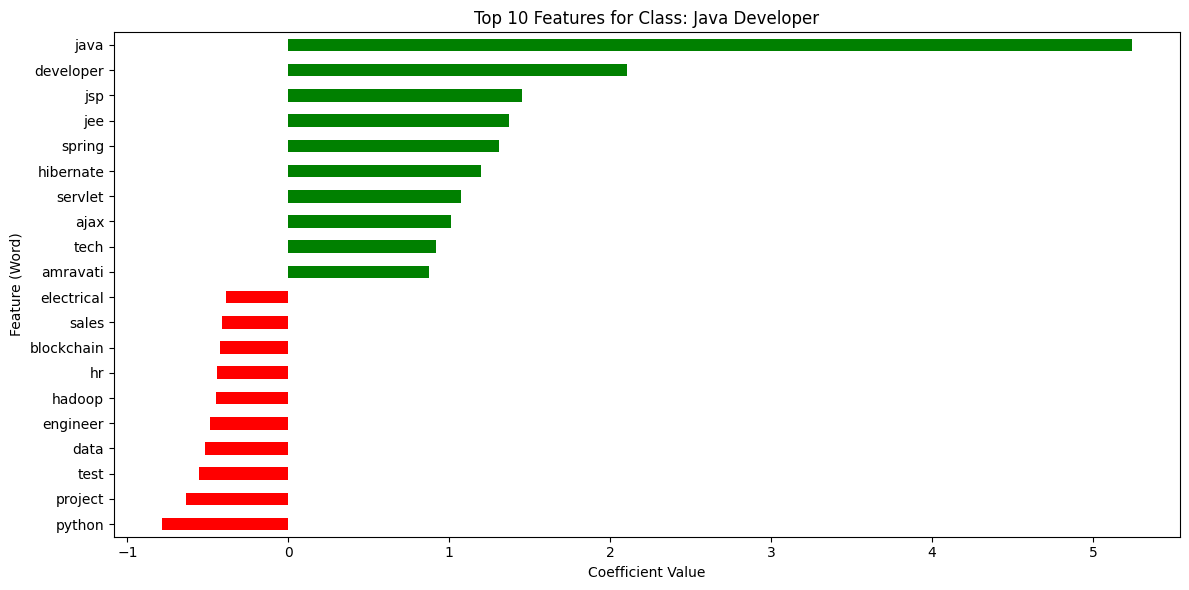


--- Class: Mechanical Engineer ---
Top Positive Features (most indicative):
mechanical     3.316136
engineering    1.427394
plastering     1.367613
machine        1.239961
design         1.068314
wave           0.988516
cnc            0.953478
association    0.927366
students       0.909262
president      0.900571
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
months       -0.698110
exprience    -0.663889
java         -0.524567
developer    -0.507898
data         -0.500994
testing      -0.469157
python       -0.417224
management   -0.397803
hr           -0.372554
business     -0.370808
dtype: float64


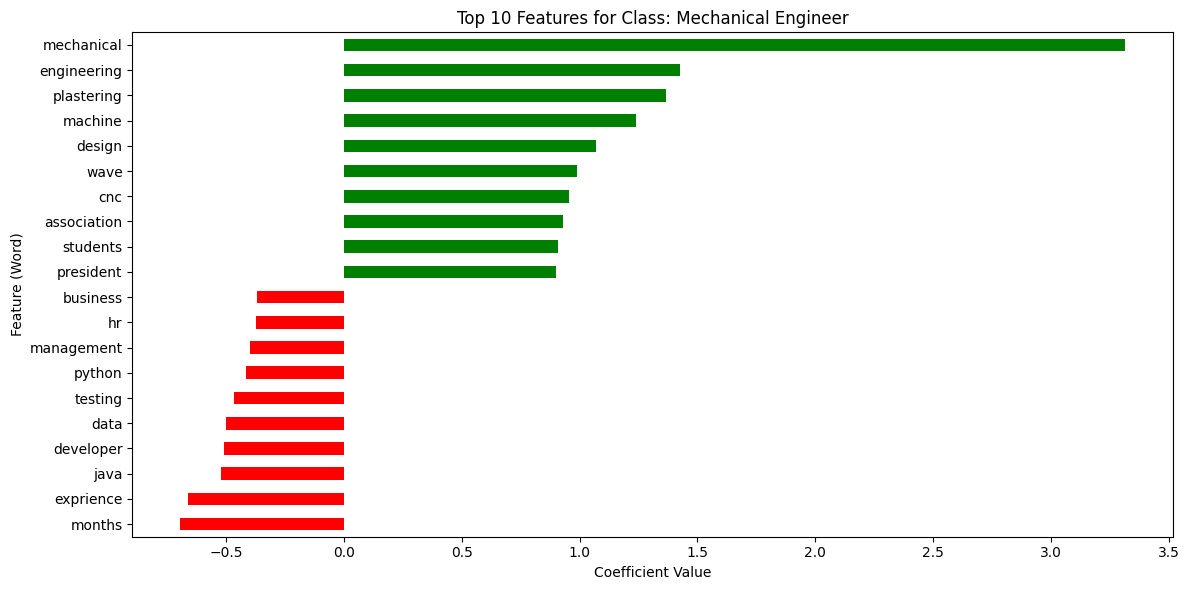


--- Class: Network Security Engineer ---
Top Positive Features (most indicative):
cisco            2.713524
network          2.248164
security         1.961226
firewall         1.325324
configuration    1.267406
firewalls        0.885619
asa              0.811610
switches         0.775440
devices          0.747802
troubleshoot     0.656312
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
java        -0.457280
developer   -0.398915
january     -0.380807
data        -0.371592
testing     -0.366733
database    -0.359673
project     -0.330185
team        -0.319669
sales       -0.307774
python      -0.298986
dtype: float64


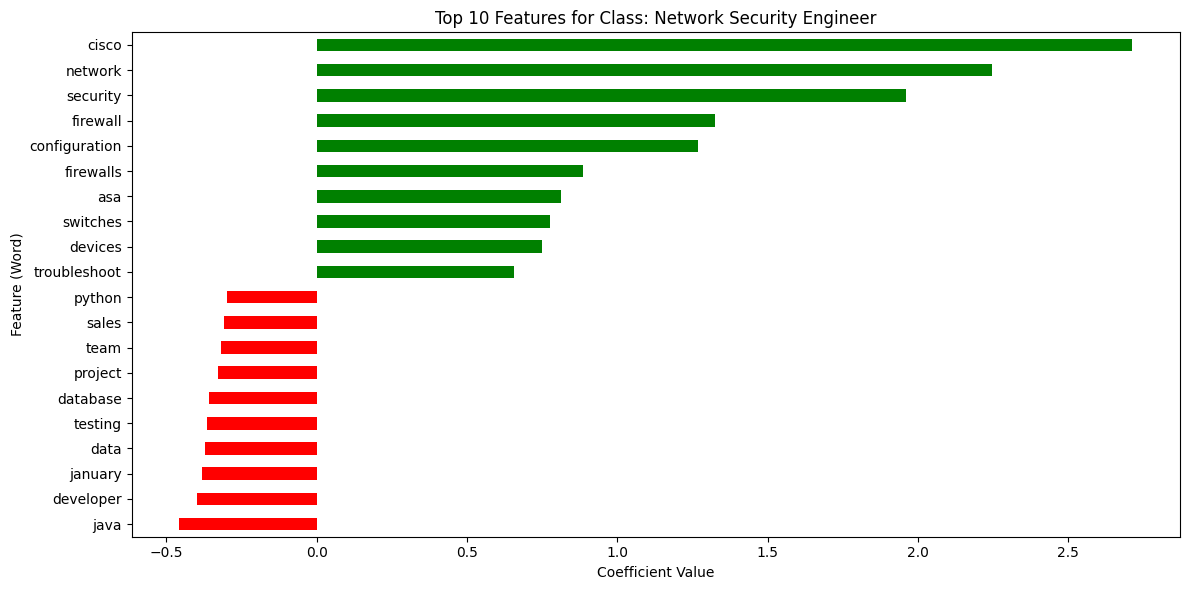


--- Class: Operations Manager ---
Top Positive Features (most indicative):
operations    2.235258
ensuring      1.403333
services      1.111121
team          1.015424
honeywell     0.932611
ges           0.919893
shipments     0.895232
prepaid       0.842589
freight       0.842101
monitored     0.810353
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
exprience     -0.757202
months        -0.665844
january       -0.488593
data          -0.462923
java          -0.447373
developer     -0.424681
year          -0.412482
maharashtra   -0.375305
pune          -0.336750
test          -0.331474
dtype: float64


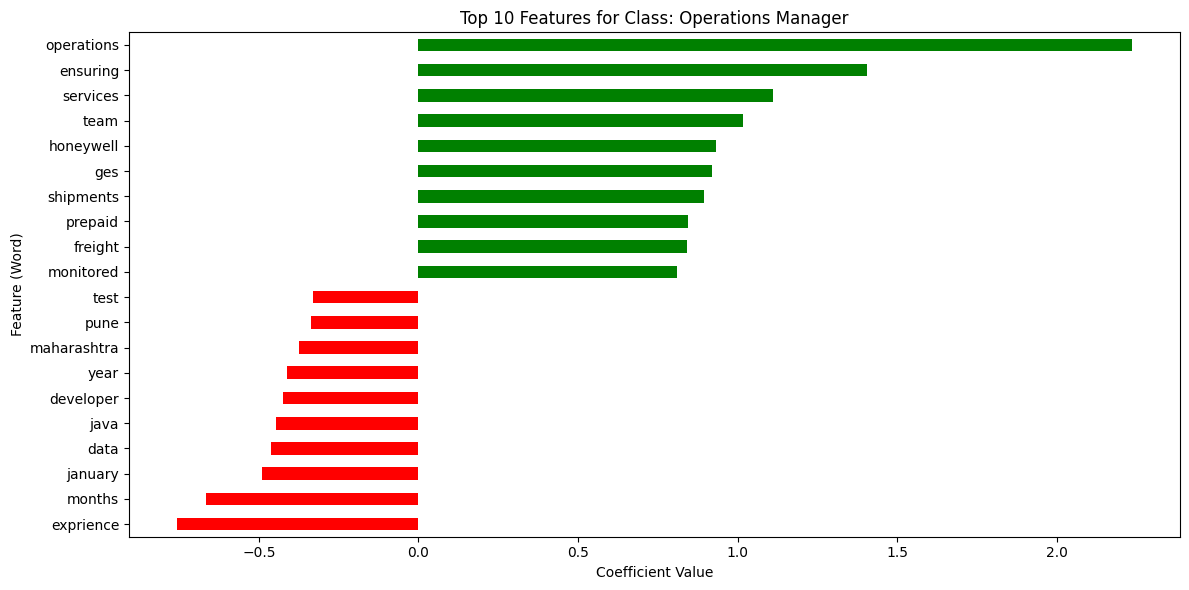


--- Class: PMO ---
Top Positive Features (most indicative):
management       1.392636
report           1.284847
sla              1.044036
pmo              1.010179
responsible      0.988878
senior           0.963905
documentation    0.860437
project          0.840018
delhi            0.810520
training         0.776943
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
year          -0.459739
testing       -0.415314
java          -0.407028
january       -0.384042
developer     -0.367564
test          -0.358948
engineering   -0.344962
python        -0.314776
application   -0.298282
mumbai        -0.284878
dtype: float64


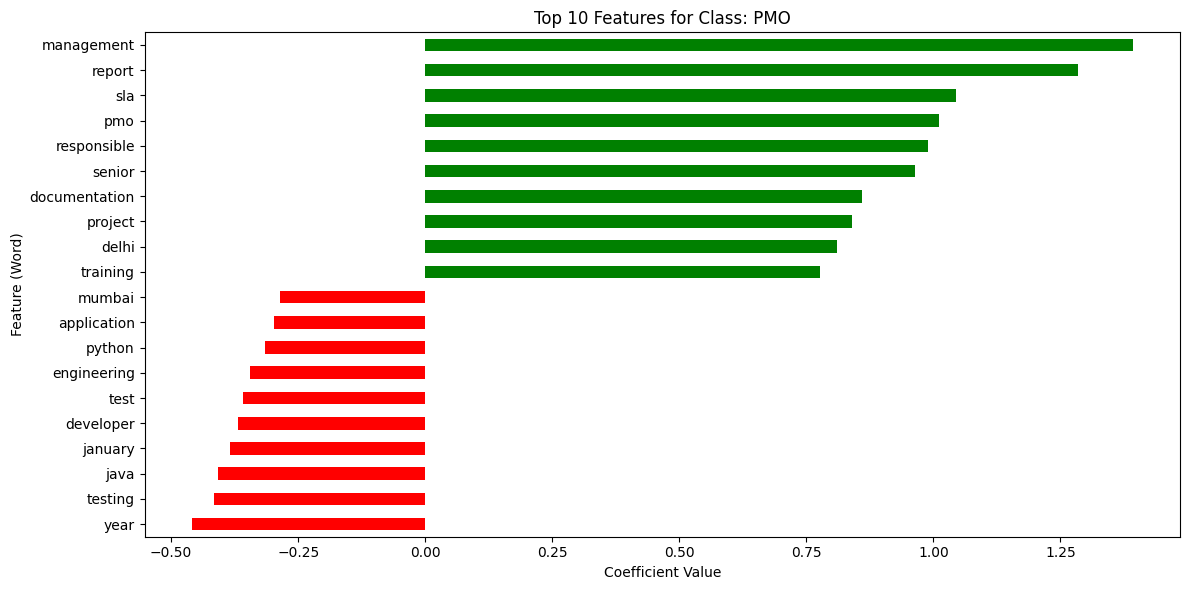


--- Class: Python Developer ---
Top Positive Features (most indicative):
python          4.147779
pune            1.723380
completed       1.353106
django          1.202739
organisation    1.108825
rest            1.073920
developer       0.940930
june            0.900720
kranti          0.856830
scrapping       0.856830
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
data         -0.512460
technology   -0.391141
sql          -0.390887
engineer     -0.382949
sales        -0.370492
hr           -0.338661
machine      -0.332831
electrical   -0.329604
test         -0.310820
learning     -0.298549
dtype: float64


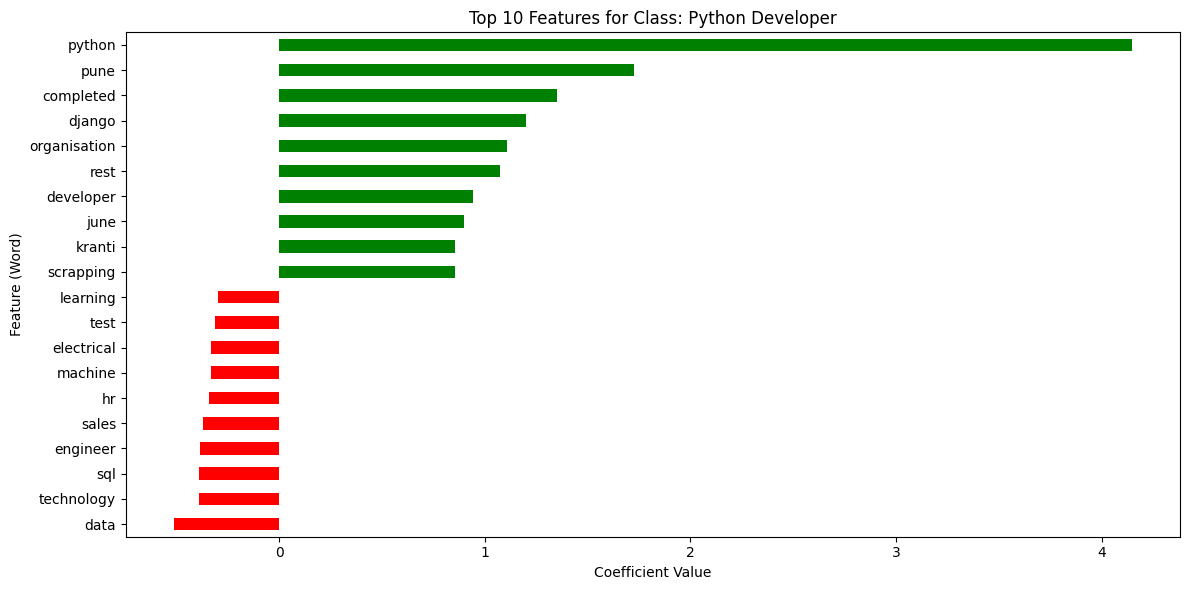


--- Class: SAP Developer ---
Top Positive Features (most indicative):
sap         4.030581
bo          1.818208
hana        1.587924
abap        1.279589
webi        0.765761
universe    0.677799
reports     0.540099
views       0.498786
users       0.483393
major       0.460327
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
exprience    -0.592328
months       -0.546338
management   -0.398178
database     -0.335730
year         -0.330557
java         -0.299973
python       -0.291708
pune         -0.281621
january      -0.279645
software     -0.277705
dtype: float64


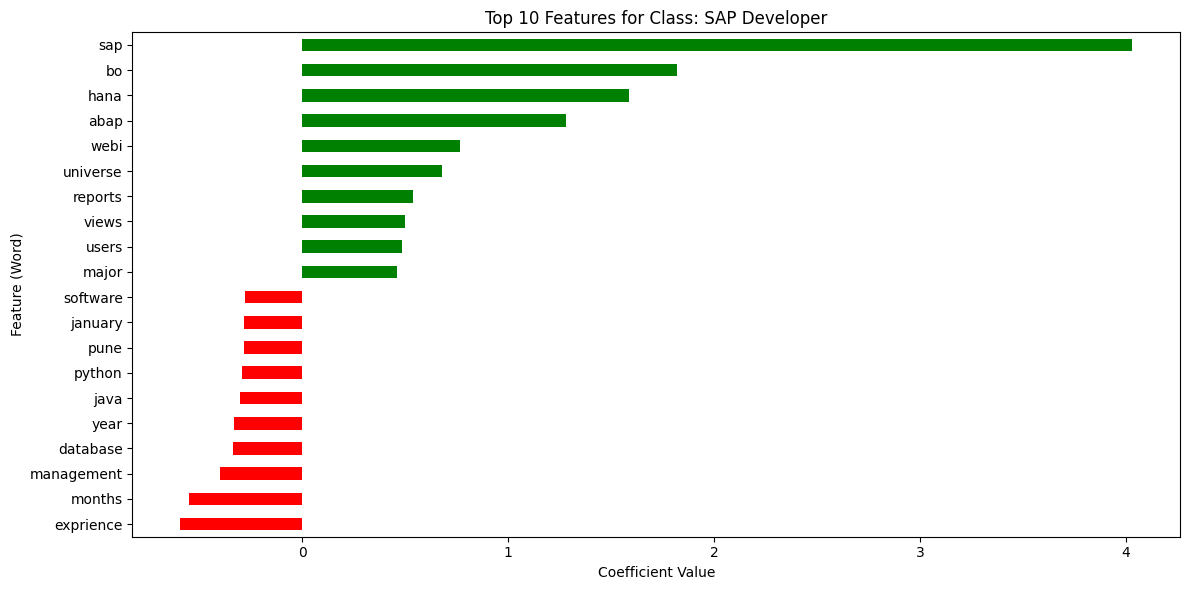


--- Class: Sales ---
Top Positive Features (most indicative):
sales         3.954867
manager       1.317454
dealership    1.287820
honda         1.287820
leads         1.247935
cricket       1.245637
marketing     1.159139
calling       1.014516
bajaj         0.863580
cold          0.770386
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
project       -0.668593
java          -0.530295
developer     -0.467508
engineering   -0.419677
data          -0.413601
testing       -0.402746
python        -0.360068
maharashtra   -0.354927
database      -0.353496
hr            -0.349863
dtype: float64


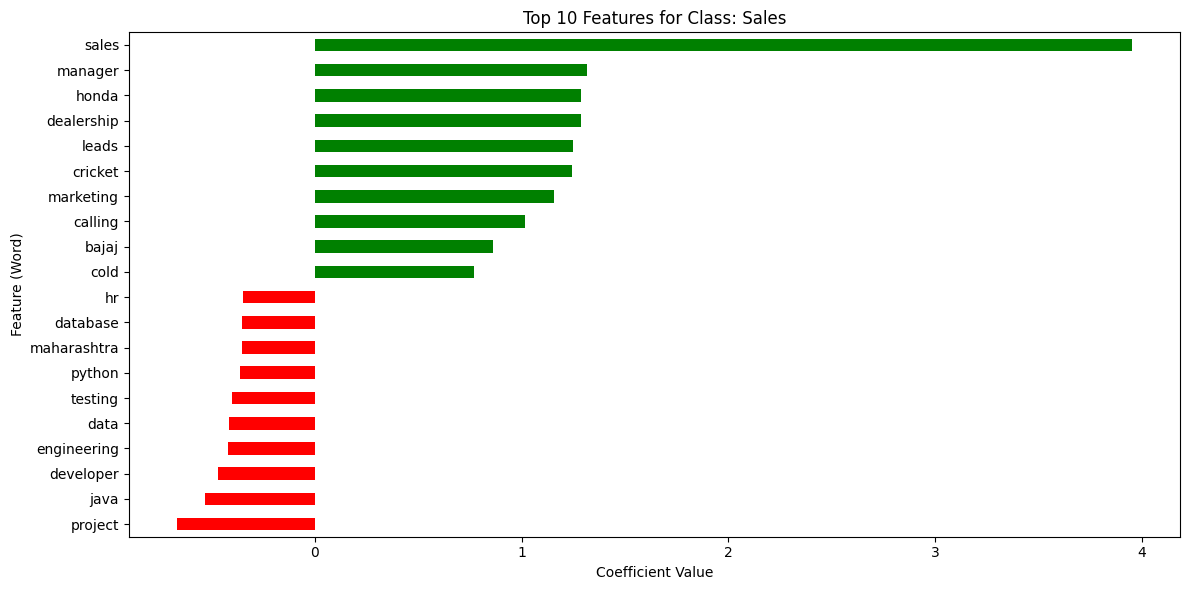


--- Class: Testing ---
Top Positive Features (most indicative):
testing        2.437180
test           1.965335
android        1.664000
pcb            1.601970
transformer    1.478373
check          1.395781
engineer       1.344216
quality        1.256152
windows        1.238462
electronics    1.149100
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
data          -0.787574
developer     -0.737966
python        -0.570551
business      -0.523490
java          -0.520908
mumbai        -0.507286
sales         -0.505584
science       -0.474461
civil         -0.446699
development   -0.442260
dtype: float64


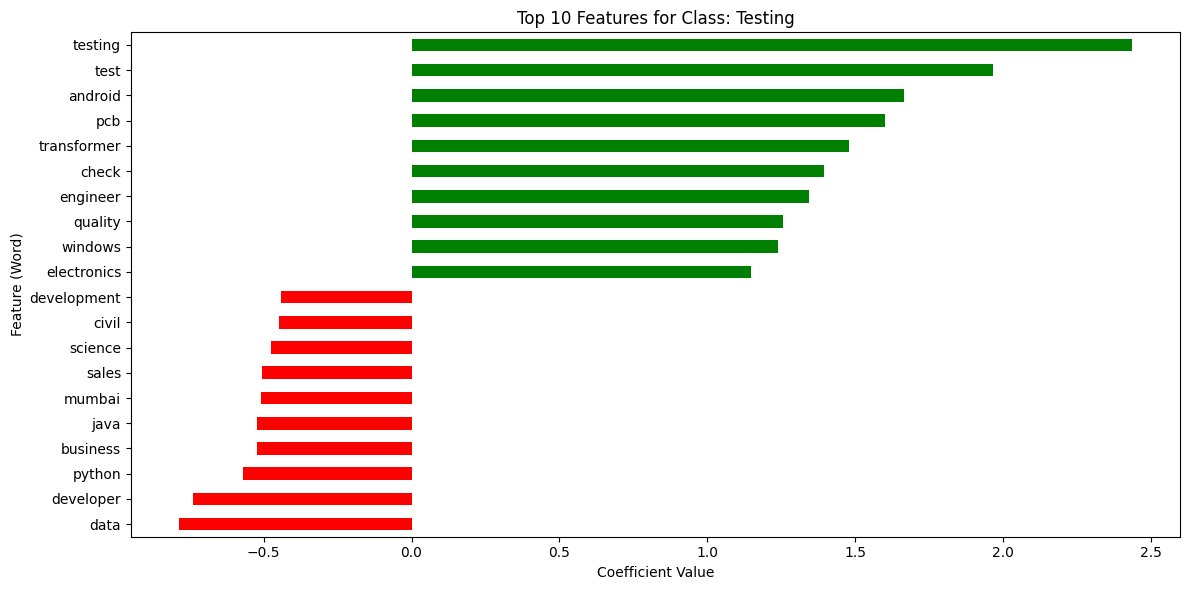


--- Class: Web Designing ---
Top Positive Features (most indicative):
allahabad    1.921737
bootstrap    1.658311
web          1.490360
salary       1.319891
ui           1.187893
php          1.179355
photoshop    1.176475
designer     1.158771
css          1.121269
synopsis     1.033795
dtype: float64

Top Negative Features (least indicative, or indicative of other classes):
testing      -0.502264
python       -0.429896
year         -0.396617
test         -0.380411
management   -0.376865
months       -0.374530
data         -0.362176
exprience    -0.354161
java         -0.351416
role         -0.315876
dtype: float64


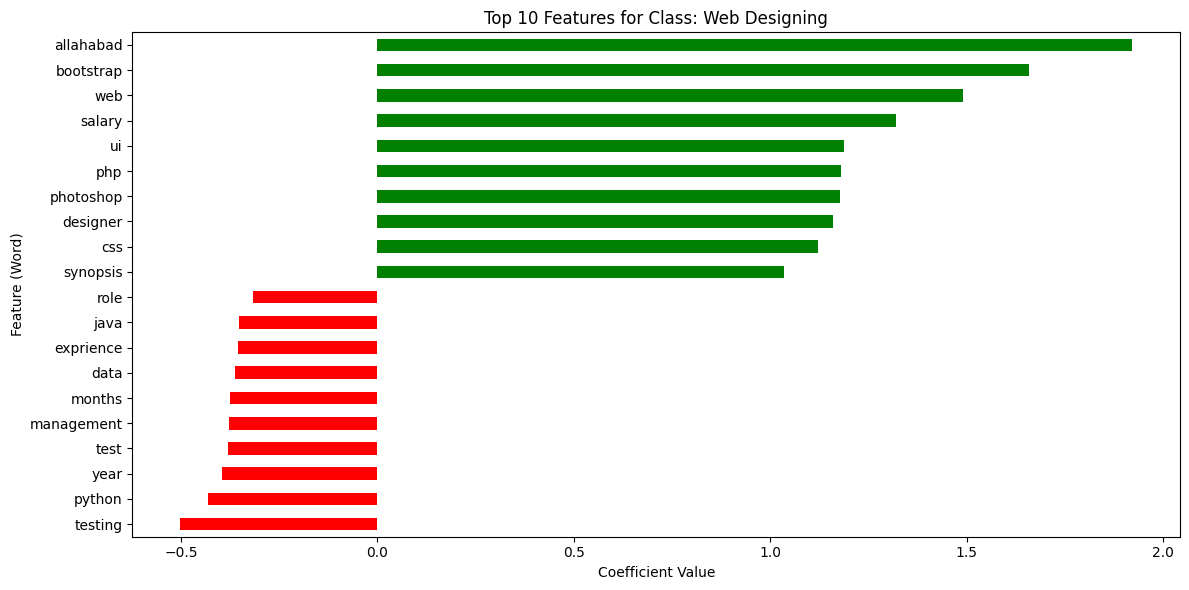

In [28]:
def plot_top_features_per_class(model, feature_names, class_labels, n_top_features=10):
    """
    Plots the top N positive and negative features for each class from a linear model.

    Args:
        model: The trained linear model (e.g., LogisticRegression).
        feature_names (list): List of feature names.
        class_labels (list): List of class labels.
        n_top_features (int): Number of top features to display for each class.
    """
    print(f"Displaying top {n_top_features} features per class for Logistic Regression:")

    for i, class_label in enumerate(class_labels):
        # Get coefficients for the current class
        # For multi-class, coef_ is (n_classes, n_features)
        coefs = model.coef_[i]

        # Create a pandas Series for easier sorting
        feature_coefs = pd.Series(coefs, index=feature_names)

        # Get top positive and negative features
        top_positive_features = feature_coefs.nlargest(n_top_features)
        top_negative_features = feature_coefs.nsmallest(n_top_features)

        print(f"\n--- Class: {class_label} ---")
        print("Top Positive Features (most indicative):")
        print(top_positive_features)
        print("\nTop Negative Features (least indicative, or indicative of other classes):")
        print(top_negative_features)

        # Plotting for better visualization
        plt.figure(figsize=(12, 6))
        combined_features = pd.concat([top_positive_features, top_negative_features])
        combined_features.sort_values(inplace=True)
        combined_features.plot(kind='barh', color=['green' if x > 0 else 'red' for x in combined_features])
        plt.title(f'Top {n_top_features} Features for Class: {class_label}')
        plt.xlabel('Coefficient Value')
        plt.ylabel('Feature (Word)')
        plt.tight_layout()
        plt.show()

# Call the function to plot top features for the Logistic Regression model
plot_top_features_per_class(log_reg_model, feature_names, class_labels, n_top_features=10)

## Model Serialization

To ensure our trained models and preprocessing tools (like the TF-IDF vectorizer and label encoder) can be reused without retraining, we need to save them. This process is called **Model Serialization**. We'll use the `joblib` library (or `pickle`) for this purpose, as it's efficient for large NumPy arrays often found in scikit-learn objects.

We will save the following components:

1.  **XGBoost Classifier (`xgb_model`):** Our best-performing model.
2.  **TF-IDF Vectorizer (`tfidf_vectorizer`):** Essential for transforming new resume text into numerical features.
3.  **Label Encoder (`label_encoder`):** Necessary for encoding target labels during training and decoding predictions during inference.

In [29]:
import joblib
import os

# Define the directory to save the models
model_dir = 'trained_models'
os.makedirs(model_dir, exist_ok=True)

# Save the XGBoost Classifier model
joblib.dump(xgb_model, os.path.join(model_dir, 'xgboost_model.joblib'))
print(f"XGBoost model saved to {os.path.join(model_dir, 'xgboost_model.joblib')}")

# Save the TF-IDF Vectorizer
joblib.dump(tfidf_vectorizer, os.path.join(model_dir, 'tfidf_vectorizer.joblib'))
print(f"TF-IDF Vectorizer saved to {os.path.join(model_dir, 'tfidf_vectorizer.joblib')}")

# Save the Label Encoder
joblib.dump(label_encoder, os.path.join(model_dir, 'label_encoder.joblib'))
print(f"Label Encoder saved to {os.path.join(model_dir, 'label_encoder.joblib')}")

print("All necessary models and preprocessing tools have been serialized and saved.")

XGBoost model saved to trained_models/xgboost_model.joblib
TF-IDF Vectorizer saved to trained_models/tfidf_vectorizer.joblib
Label Encoder saved to trained_models/label_encoder.joblib
All necessary models and preprocessing tools have been serialized and saved.


## K-Fold Cross Validation

To address potential overfitting concerns raised by the high accuracy scores, we apply **Stratified K-Fold Cross Validation (K=5)**.

Unlike a single train/test split, K-Fold:
- Trains and evaluates the model **5 times** on different data subsets
- Gives a **mean accuracy** that is more reliable and less sensitive to random splitting
- Reports **standard deviation** — a low Std Dev (< 0.03) means the model is genuinely stable, not just overfitting one split

`StratifiedKFold` is used (instead of regular KFold) to preserve class proportions in each fold, which is critical given the imbalanced dataset (20 to 84 samples per category).

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt

# ── Step 1: Encode target variable ─────────────────────────────────────────
# Use a fresh LabelEncoder on the full dataset to avoid conflicts
full_label_encoder = LabelEncoder()
y_encoded_full = full_label_encoder.fit_transform(df['Category'])
print(f"Shape of y_encoded_full: {y_encoded_full.shape}")
print(f"Classes: {list(full_label_encoder.classes_)[:5]} ... ({len(full_label_encoder.classes_)} total)")

# ── Step 2: Define StratifiedKFold ─────────────────────────────────────────
# StratifiedKFold preserves class proportions in each fold
# This is essential for imbalanced datasets like ours (20-84 samples/class)
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
print(f"\nPerforming {n_splits}-Fold Stratified Cross-Validation...")

# ── Step 3: Define models ──────────────────────────────────────────────────
# Fresh (unfitted) model instances for cross_val_score
models_cv = {
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, solver="liblinear"),
    "XGBoost":             xgb.XGBClassifier(
                               objective="multi:softmax",
                               num_class=len(full_label_encoder.classes_),
                               eval_metric="mlogloss",
                               random_state=42,
                               verbosity=0
                           ),
}

# ── Step 4: Run cross-validation ───────────────────────────────────────────
print("\n" + "=" * 60)
cv_results = {}

for name, model in models_cv.items():
    scores = cross_val_score(
        model,
        tfidf_matrix,        # Full TF-IDF matrix (all 962 samples)
        y_encoded_full,      # Encoded labels for full dataset
        cv=skf,
        scoring="accuracy",
        n_jobs=-1            # Use all available CPU cores
    )
    cv_results[name] = scores

    print(f"\n{name}:")
    print(f"  Fold Scores : {scores.round(4)}")
    print(f"  Mean Acc    : {scores.mean():.4f}  ({scores.mean()*100:.2f}%)")
    print(f"  Std Dev     : {scores.std():.4f}")
    if scores.std() < 0.03:
        print(f"  Status      : Stable — consistent across all folds")
    elif scores.std() < 0.05:
        print(f"  Status      : Moderate variation — acceptable")
    else:
        print(f"  Status      : High variation — possible overfitting")

print("\n" + "=" * 60)
print("\nSummary Table:")
print(f"  {'Model':<25} {'Mean Acc':<12} {'Std Dev':<10} {'Status'}")
print("  " + "-" * 60)
for name, scores in cv_results.items():
    status = "Stable" if scores.std() < 0.03 else "Moderate" if scores.std() < 0.05 else "Overfitting?"
    print(f"  {name:<25} {scores.mean():.4f}       {scores.std():.4f}      {status}")

# ── Step 5: Visualization ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart — Mean accuracy per model
names  = list(cv_results.keys())
means  = [cv_results[n].mean() for n in names]
stds   = [cv_results[n].std()  for n in names]
colors = ["#1565C0", "#1976D2", "#42A5F5"]

bars = axes[0].bar(names, means, yerr=stds, color=colors,
                   capsize=6, edgecolor="white", linewidth=1.2)
axes[0].set_title("Mean CV Accuracy per Model", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.8, 1.0)
for bar, mean in zip(bars, means):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f"{mean*100:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=11)
axes[0].tick_params(axis="x", rotation=15)

# Box plot — Score distribution across folds
data_to_plot = [cv_results[n] for n in names]
bp = axes[1].boxplot(data_to_plot, labels=names, patch_artist=True,
                     medianprops=dict(color="white", linewidth=2))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
axes[1].set_title("Score Distribution Across Folds", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Accuracy per Fold")
axes[1].set_ylim(0.8, 1.0)
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle("K-Fold Cross Validation Results (K=5)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("kfold_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nChart saved as kfold_results.png")
